# Laboratorio 9: Series de tiempo y forecasting · Parte 2
##  Deep Learning y Sistemas Inteligentes

Melisa Dayana Mendizabal Melendez 23778
Renato Manuel Rojas Roldán 23813

Este notebook continúa `parte1_datos_y_modelos.ipynb` **sin volver a correrlo**: lee el panel limpio, la escala del MASE y los resultados de la Parte 1 desde `data/`, `preds/` y `results/`, y usa el mismo protocolo `backtest()`.

| Sección | Contenido |
|---|---|
| 5 | Modelos de librería: N-HiTS, TCN, PatchTST, TFT, DeepAR (NeuralForecast) y Chronos-Bolt *zero-shot* |
| 5.2 | Iteraciones de hiperparámetros (solo validación): L, meses de historia, normalización, hidden, dropout, lr y batch |
| 5.3 | Modelo local (uno por cliente, 10 clientes) contra el global |
| 4 | Reentrenamiento mensual del mejor modelo de DL y de los baselines |
| 6 | MASE con H = 168, tabla comparativa final y 3 gráficas |
| 8 | Sensibilidad a la semilla y números de apoyo para la discusión |

### Archivos que exporta

| Archivo | Contenido |
|---|---|
| `lab9/neural.py` | Envoltorios `NFModel` (NeuralForecast) y `ChronosBolt` con el contrato `fit/predict` |
| `preds/<modelo>.parquet` | Pronósticos de prueba de cada modelo nuevo |
| `preds/test_predictions.parquet` | **Entregable:** todos los modelos (`unique_id, ds, modelo, y_hat`) |
| `results/test_metrics_parte2.csv` | Métricas de prueba de los modelos nuevos |
| `results/test_metrics.csv` | Tabla comparativa final (Parte 1 + Parte 2), ordenada por MASE |
| `results/val_iters_parte2.csv` | Una fila por iteración de 5.2 (validación) |
| `results/test_metrics_H168.csv`, `test_refit_MS.csv`, `test_seeds.csv`, `local_vs_global.csv` | H = 168, reentrenamiento mensual, semillas y 5.3 |
| `results/runs.csv` + `results/history/` | Registro de cada entrenamiento (se agregan las corridas nuevas) |

**Caché.** Cada corrida guarda su fila y sus pronósticos al terminar. Si el kernel se cae, al volver a ejecutar se cargan los resultados ya calculados y se continúa donde quedó (`RECOMPUTE = True` fuerza a recalcular). Con `LAB9_QUICK=1` todo corre con 20 clientes y muy pocas epochs, y escribe en `quick/` para no tocar los resultados reales.

### Configuración

In [1]:
%load_ext autoreload
%autoreload 2

import gc, os, json, time, warnings
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# QUICK=1 (variable de entorno) corre todo con 20 clientes y muy pocas epochs para depurar.
QUICK = os.environ.get("LAB9_QUICK", "0") == "1"
# Cada corrida se guarda al terminar; con False se reutiliza lo que ya está en results/ y preds/.
RECOMPUTE = False

# Misma paleta y estilo que la Parte 1.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GRAY = "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110,
})

In [2]:
from lab9 import config as C, data as D, backtest as BT, metrics as ME, models as MD, training as TR
from lab9.baselines import LightGBMGlobal, StatsForecastModel

# Salidas de la Parte 1: solo se leen.
P1_RESULTS, P1_PREDS = C.RESULTS_DIR, C.PREDS_DIR
if QUICK:
    # La corrida corta escribe en quick/ (ignorado por git) para no mezclarse con los resultados reales.
    C.RESULTS_DIR, C.PREDS_DIR, C.FIG_DIR = (C.ROOT / "quick" / d for d in ("results", "preds", "figures"))
C.ensure_dirs()
torch.manual_seed(C.SEED); np.random.seed(C.SEED)
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no")
print("QUICK =", QUICK, "| resultados en", C.RESULTS_DIR)


def savefig(fig, name):
    fig.savefig(C.FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

torch 2.13.0+cu126 | GPU: NVIDIA GeForce RTX 4060 Laptop GPU
QUICK = False | resultados en C:\Users\darta\OneDrive\Desktop\REN\UVG\2026\Segundo ciclo\Deep\deep_Lab9\results


### Datos y resultados de la Parte 1

Mismo panel de 315 clientes, misma escala del MASE (MAE in-sample del seasonal naive m = 24, solo entrenamiento) y misma normalización por ventana para las redes propias.

In [3]:
panel = D.load_panel()                                   # los mismos 315 clientes
stats = pd.read_csv(C.STATS_PATH)                        # escala del MASE
res1 = pd.read_csv(P1_RESULTS / "test_metrics_parte1.csv")
runs1 = pd.read_csv(P1_RESULTS / "runs.csv")
if QUICK:
    panel = panel.subset(panel.ids[:20])
print(f"Panel: {panel.N} clientes x {len(panel.times):,} horas ({panel.times[0]} … {panel.times[-1]})")
display(res1[["model", "family", "MASE", "MAE", "MASE_xmas", "train_time_s"]].round(3))

Panel: 315 clientes x 26,304 horas (2012-01-01 00:00:00 … 2014-12-31 23:00:00)


,model,family,MASE,MAE,MASE_xmas,train_time_s
0,Seq2Seq,Encoder–decoder,0.831,43.140,1.414,1222.926
1,LSTM_AR,Recurrentes,0.832,43.304,1.394,1291.780
2,MLP,MLP y lineales,0.836,43.347,1.449,46.132
3,LSTM,Recurrentes,0.871,44.641,1.566,913.970
4,LightGBM,Árboles,0.880,43.852,1.717,47.232
5,NLinear,MLP y lineales,0.882,45.443,1.829,31.915
6,DLinear,MLP y lineales,0.885,45.519,1.837,22.323
7,MSTL,Baseline,0.926,48.634,1.964,0.000
8,SeasonalNaive24,Baseline,1.044,50.010,2.235,0.000
9,SeasonalNaive168,Baseline,1.074,56.625,1.623,0.000


### Envoltorios de librería: `lab9/neural.py`

Igual que los modelos de la Parte 1, los modelos de librería pasan por `BT.backtest()`; solo necesitan `name`, `fit(panel, val_start)` y `predict(y_hist, times_hist, times_future)`.

- **`NFModel`** envuelve cualquier modelo de NeuralForecast.
  - **Datos que ve.** `fit` recibe el panel truncado en 2014-09-30 y usa julio–septiembre como `val_size` (early stopping). `predict` recibe solo las últimas L horas.
  - **Covariables.** Los modelos que las aceptan reciben el mismo calendario de la Parte 1 (`CAL_FEATURES`) como covariables futuras.
  - **Solo se normaliza `y`.** Por defecto NeuralForecast también normaliza las covariables con la media y la desviación de la ventana. El seno/coseno del mes es constante dentro de una semana y su desviación sale ~1e-8, así que el día que cambia el mes la covariable se dividía entre ~1e-6. Eso producía pronósticos de ±50,000 kWh el 1 de octubre y el 1 de diciembre. El calendario ya está en [-1, 1], así que `scale_y_only` deja de escalarlo.
  - **Mejores pesos.** El early stopping de NeuralForecast solo detiene el entrenamiento. El callback `BestWeights` restaura los pesos del mejor chequeo de validación, igual que `TorchForecaster`.
  - **Ventanas.** `step_size=24` hace que las ventanas de entrenamiento y validación terminen a las 23:00, igual que los orígenes del backtest.
  - **Pronóstico puntual de DeepAR.** Es la **mediana**, que minimiza el MAE. P10 y P90 salen del intervalo central de 80%.
- **`ChronosBolt`** no se entrena: `fit` no hace nada y `predict` llama a `predict_quantiles` con las últimas 2048 horas (el contexto máximo de Bolt).

In [4]:
%%writefile lab9/neural.py
"""Modelos de librería con el mismo contrato fit/predict de backtest(): NeuralForecast y Chronos-Bolt."""
import copy
import logging
import time
import warnings

import numpy as np
import pandas as pd
import torch

from . import config as C
from .data import CAL_FEATURES, calendar_features
from .training import hardware

# Lightning imprime varias líneas en cada fit/predict; en el backtest se llama 92 veces. Se importa
# antes de bajar el nivel de sus loggers porque al importarse los vuelve a poner en INFO.
import pytorch_lightning  # noqa: E402,F401

for _name in ("pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"):
    logging.getLogger(_name).setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message=".*predict_dataloader.*")

TRAINER_KW = dict(enable_progress_bar=False, enable_model_summary=False, logger=False,
                  enable_checkpointing=False, accelerator="gpu" if torch.cuda.is_available() else "cpu",
                  devices=1)


class BestWeights(pytorch_lightning.Callback):
    """Guarda en memoria los pesos con la menor pérdida de validación.

    El early stopping de NeuralForecast solo detiene el entrenamiento: se queda con los pesos del último
    paso, que pueden estar `patience` chequeos después del mejor. Este callback permite restaurarlos, igual
    que TorchForecaster con las redes propias.
    """

    def __init__(self):
        self.best, self.step, self.state = np.inf, None, None

    def on_validation_end(self, trainer, pl_module):
        v = trainer.callback_metrics.get("ptl/val_loss")
        if not trainer.sanity_checking and v is not None and np.isfinite(float(v)) and float(v) < self.best:
            self.best, self.step = float(v), trainer.global_step
            self.state = {k: t.detach().clone() for k, t in pl_module.state_dict().items()}


_Y_ONLY = {}


def scale_y_only(cls):
    """Subclase de un modelo de NeuralForecast que normaliza por ventana solo la serie objetivo.

    NeuralForecast normaliza también las covariables con la media y la desviación de la ventana de
    entrada. El seno/coseno del mes es constante dentro de una semana: su desviación sale ~1e-8 por
    redondeo (no exactamente 0, que NF sí reemplaza por 1), así que el día que cambia el mes la
    covariable se divide entre ~1e-6 y la red recibe valores de ~1e5 (pronósticos de ±50,000 kWh el
    1 de octubre o el 1 de diciembre). El calendario ya está en [-1, 1] y {0, 1}: no hace falta escalarlo.
    """
    if cls not in _Y_ONLY:
        _Y_ONLY[cls] = type(cls.__name__, (cls,), {"_get_temporal_exogenous_cols": lambda self, temporal_cols: []})
    return _Y_ONLY[cls]


def to_long(Y, times, ids, exog=True):
    """Matriz (N, t) -> formato largo de Nixtla (unique_id, ds, y [+ calendario])."""
    times = pd.DatetimeIndex(times)
    df = pd.DataFrame({"unique_id": np.repeat(ids, len(times)), "ds": np.tile(times.values, len(ids)),
                       "y": np.asarray(Y, dtype=np.float32).reshape(-1)})
    if exog:
        cal = calendar_features(times).to_numpy(np.float32)
        df[CAL_FEATURES] = np.tile(cal, (len(ids), 1))
    return df


class NFModel:
    """Envuelve un modelo de NeuralForecast con el contrato fit/predict de backtest().

    - El modelo se construye de nuevo en cada fit() (clase + hiperparámetros), así el reentrenamiento
      mensual parte de pesos nuevos y la semilla se controla con `random_seed`.
    - fit() recibe el panel ya truncado; las últimas horas desde `val_start` son el bloque de
      validación de NeuralForecast (`val_size`), que solo se usa para early stopping. Al terminar se
      restauran los pesos del mejor chequeo de validación (BestWeights).
    - step_size=24: las ventanas de entrenamiento y validación avanzan un día y terminan a las 23:00,
      igual que los orígenes del backtest. Además baja la validación de ~690k a ~29k ventanas.
    - predict() entrega a NeuralForecast solo las últimas L horas (y su calendario) y el calendario de
      las H horas futuras. La normalización es por ventana (scaler temporal o RevIN), sin fuga, y
      solo se aplica a la serie objetivo (ver scale_y_only).
    - Si el modelo es probabilístico (DistributionLoss con level=[80]) devuelve P10, P50 y P90; el
      pronóstico puntual es la mediana, que es lo que minimiza el MAE.
    """

    def __init__(self, name, cls, L=168, H=C.H, exog=True, history_months=None, family="", strategy="",
                 seed=C.SEED, **kw):
        self.name, self.cls, self.L, self.H, self.exog = name, cls, L, H, exog
        self.history_months, self.family, self.strategy, self.seed = history_months, family, strategy, seed
        self.uses_cov = exog
        self.kw = dict(kw)
        self.kw.setdefault("step_size", 24)

    def config(self):
        hp = {k: v for k, v in self.kw.items() if isinstance(v, (int, float, str, bool))}
        if "loss" in self.kw:
            hp["loss"] = type(self.kw["loss"]).__name__
        return {"model": self.name, "family": self.family, "strategy": self.strategy, "uses_cov": self.uses_cov,
                "L": self.L, "H": self.H, "history_months": self.history_months or 30, "seed": self.seed,
                "nf_class": self.cls.__name__, **hp}

    def _build(self):
        extra = {"futr_exog_list": list(CAL_FEATURES)} if self.exog else {}
        return scale_y_only(self.cls)(h=self.H, input_size=self.L, alias=self.name, random_seed=self.seed,
                                      callbacks=[BestWeights()], **extra, **copy.deepcopy(self.kw), **TRAINER_KW)

    def fit(self, panel, val_start):
        from neuralforecast import NeuralForecast
        val_pos = panel.idx(val_start)
        start = 0
        if self.history_months:      # historia de entrenamiento limitada (sección 5.2)
            first = pd.Timestamp(val_start) - pd.DateOffset(months=self.history_months)
            start = max(0, panel.idx(first) - self.L)
        self.ids = list(panel.ids)
        df = to_long(panel.Y[:, start:], panel.times[start:], self.ids, self.exog)
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        t0 = time.perf_counter()
        self.nf = NeuralForecast(models=[self._build()], freq="h")
        self.nf.fit(df=df, val_size=len(panel.times) - val_pos)
        self.train_time = time.perf_counter() - t0
        self.gpu_peak_mb = torch.cuda.max_memory_allocated() / 2**20 if torch.cuda.is_available() else 0.0
        self.model = self.nf.models[0]
        # NeuralForecast copia el modelo al entrenar: el callback que se usó está en su trainer_kwargs.
        cbs = self.model.trainer_kwargs.get("callbacks") or []
        best = next((cb for cb in cbs if isinstance(cb, BestWeights)), None)
        self.best_step = None
        if best is not None and best.state is not None:
            self.model.load_state_dict(best.state)
            self.best_step = best.step
            self.model.trainer_kwargs["callbacks"] = [cb for cb in cbs if cb is not best]
        self.n_params = sum(p.numel() for p in self.model.parameters())
        self.n_trainable = sum(p.numel() for p in self.model.parameters() if p.requires_grad)
        self.history = self._history()
        return self

    def _history(self):
        """Curvas de pérdida: una fila por chequeo de validación (cada `val_check_steps` pasos)."""
        tr = pd.DataFrame(self.model.train_trajectories, columns=["step", "train_loss"])
        va = pd.DataFrame(self.model.valid_trajectories, columns=["step", "val_loss"])
        if va.empty:
            return tr.assign(val_loss=np.nan).to_dict("records")
        tr["bin"] = np.searchsorted(va["step"].values, tr["step"].values)
        va["train_loss"] = tr.groupby("bin")["train_loss"].mean().reindex(range(len(va))).values
        return va[["step", "train_loss", "val_loss"]].to_dict("records")

    def predict(self, y_hist, times_hist, times_future):
        L = min(self.L, y_hist.shape[1])
        hist = to_long(y_hist[:, -L:], times_hist[-L:], self.ids, self.exog)
        futr = None
        if self.exog:
            futr = to_long(np.zeros((len(self.ids), len(times_future))), times_future, self.ids).drop(columns="y")
        fc = self.nf.predict(df=hist, futr_df=futr)
        fc = fc.set_index(["unique_id", "ds"]).loc[pd.MultiIndex.from_product([self.ids, times_future])]
        pick = lambda col: fc[col].to_numpy(np.float32).reshape(len(self.ids), len(times_future))
        if f"{self.name}-lo-80" in fc:      # el intervalo central de 80% va de P10 a P90
            med = pick(f"{self.name}-median")
            return {"mean": med, "q0.1": pick(f"{self.name}-lo-80"), "q0.5": med,
                    "q0.9": pick(f"{self.name}-hi-80")}
        return pick(self.name)

    def summary(self):
        hist = pd.DataFrame(self.history)
        best = hist.loc[hist["val_loss"].idxmin()] if hist["val_loss"].notna().any() else None
        return {**self.config(), "params_total": self.n_params, "params_trainable": self.n_trainable,
                "steps_run": int(self.model.train_trajectories[-1][0]) + 1 if self.model.train_trajectories else np.nan,
                "best_step": self.best_step if self.best_step is not None else np.nan,
                "train_time_s": self.train_time, "gpu_peak_mb": self.gpu_peak_mb,
                "val_loss": best["val_loss"] if best is not None else np.nan, "hardware": hardware()}


class ChronosBolt:
    """Chronos-Bolt zero-shot: no se entrena; fit() no hace nada y predict() solo hace inferencia.

    Recibe las últimas `context` horas de cada serie (2048 es el contexto máximo de Bolt) y devuelve
    los cuantiles P10, P50 y P90; el pronóstico puntual es la mediana.
    """

    def __init__(self, name="ChronosBolt", model_id="amazon/chronos-bolt-small", context=2048,
                 batch_size=256, device=None):
        from chronos import BaseChronosPipeline
        self.name, self.model_id, self.context, self.batch_size = name, model_id, context, batch_size
        self.family, self.strategy, self.uses_cov, self.L = "Fundacional", "multi-salida (directa)", False, context
        device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.pipeline = BaseChronosPipeline.from_pretrained(
            model_id, device_map=device, torch_dtype=torch.bfloat16 if device == "cuda" else torch.float32)
        params = list(self.pipeline.model.parameters())
        self.n_params = self.n_trainable = sum(p.numel() for p in params)
        self.train_time = 0.0

    def fit(self, panel, val_start=None):
        return self

    @torch.no_grad()
    def predict(self, y_hist, times_hist, times_future):
        ctx = torch.as_tensor(np.asarray(y_hist[:, -self.context:]), dtype=torch.float32)
        # Más allá de 64 pasos Bolt realimenta su propia mediana y la memoria crece mucho: con H = 168 un lote
        # de 256 series pide ~7 GB (y en una GPU de 8 GB Windows desborda a la RAM); con 64 bastan ~2 GB.
        bs = self.batch_size if len(times_future) <= 64 else min(self.batch_size, 64)
        qs = []
        for i in range(0, len(ctx), bs):
            q, _ = self.pipeline.predict_quantiles(ctx[i:i + bs], prediction_length=len(times_future),
                                                   quantile_levels=[0.1, 0.5, 0.9])
            qs.append(q.float().cpu())
        q = torch.cat(qs).numpy()                                              # (N, H, 3)
        return {"mean": q[..., 1], "q0.1": q[..., 0], "q0.5": q[..., 1], "q0.9": q[..., 2]}

Overwriting lab9/neural.py


### Utilidades: catálogo de modelos, caché y registro

- **`FACTORIES`** construye cualquier modelo por nombre base, más los cambios de hiperparámetros. Así el mismo modelo se puede repetir con otra semilla, otro H o reentrenamiento mensual sin copiar su configuración.
  - Los modelos de la Parte 1 se reconstruyen con la **misma configuración del notebook 1**: `TRAIN_KW`, LSTM de 2 capas con hidden 128, MLP 2×512.
- **`run_val`** corre `backtest(split="val")` y registra la iteración en `results/val_iters_parte2.csv`. Las redes propias y las de NeuralForecast también dejan su curva por epoch o por paso en `results/runs.csv` + `results/history/`.
- **`run_test`** corre `backtest(split="test")`, guarda `preds/<modelo>.parquet` y agrega la fila de métricas a la tabla correspondiente.
  - Con `fit=False` reutiliza los pesos ya entrenados en `run_val`. Ambos entrenan exactamente igual (datos hasta 2014-09-30, validación jul–sep), así que no hace falta entrenar dos veces y la prueba se usa una sola vez.

In [5]:
from neuralforecast.models import NHITS, TCN, PatchTST, TFT, DeepAR
from neuralforecast.losses.pytorch import DistributionLoss, MAE, MQLoss
from statsforecast.models import Naive, SeasonalNaive, MSTL, AutoETS
from lab9 import neural as NN

HW_CPU = f"CPU ({os.cpu_count()} hilos)"
HW_GPU = TR.hardware()

# Misma configuración de entrenamiento que la Parte 1 (notebook 1, celda de TRAIN_KW).
TRAIN_KW = (dict(max_epochs=1, samples_per_epoch=5_000) if QUICK
            else dict(max_epochs=30, patience=5, samples_per_epoch=200_000))
TRAIN_KW.update(norm="window", batch_size=512, lr=1e-3, loss="mae")
RNN_KW = dict(hidden=128, n_layers=2, dropout=0.1, cell="lstm")
MLP_KW = dict(hidden=512, n_layers=2, dropout=0.1)
# NeuralForecast: hasta 2000 pasos, validación cada 100 y early stopping tras 5 chequeos sin mejora.
NF_KW = (dict(max_steps=20, val_check_steps=10, early_stop_patience_steps=2) if QUICK
         else dict(max_steps=2000, val_check_steps=100, early_stop_patience_steps=5))
LGB_KW = dict(max_rows=300_000, num_boost_round=50) if QUICK else {}


def own(name, build, family, strategy, uses_cov, **kw):
    return TR.TorchForecaster(name, build, family=family, strategy=strategy, uses_cov=uses_cov, **{**TRAIN_KW, **kw})


def nf(name, cls, family, strategy, exog=True, **kw):
    return NN.NFModel(name, cls, exog=exog, family=family, strategy=strategy, **{**NF_KW, **kw})


def sf(name, sf_model, input_size, n_jobs=1):
    return lambda name=name, H=None, **kw: StatsForecastModel(name, sf_model, input_size=input_size, n_jobs=n_jobs)


FACTORIES = {
    # --- Parte 1 (misma configuración) ---
    "MLP": lambda name="MLP", arch={}, **kw: own(name, partial(MD.build_mlp, **{**MLP_KW, **arch}),
                                                 "MLP y lineales", "multi-salida", True, **kw),
    "DLinear": lambda name="DLinear", **kw: own(name, partial(MD.build_dlinear, kernel=25),
                                               "MLP y lineales", "multi-salida", False, **kw),
    "NLinear": lambda name="NLinear", **kw: own(name, MD.build_nlinear, "MLP y lineales", "multi-salida", False, **kw),
    "LSTM": lambda name="LSTM", arch={}, **kw: own(name, partial(MD.build_rnn_mo, **{**RNN_KW, **arch}),
                                                   "Recurrentes", "multi-salida", True, **kw),
    "LSTM_AR": lambda name="LSTM_AR", arch={}, **kw: own(name, partial(MD.build_rnn_ar, **{**RNN_KW, **arch}),
                                                         "Recurrentes", "autorregresiva", True, **kw),
    "Seq2Seq": lambda name="Seq2Seq", arch={}, **kw: own(name, partial(MD.build_seq2seq, **{**RNN_KW, **arch},
                                                                       feed_prev=False),
                                                         "Encoder–decoder", "encoder–decoder", True, **kw),
    "LightGBM": lambda name="LightGBM", H=None, **kw: LightGBMGlobal(name, **{**LGB_KW, **kw}),
    "Naive": sf("Naive", Naive(), 24),
    "SeasonalNaive24": sf("SeasonalNaive24", SeasonalNaive(24), 24),
    "SeasonalNaive168": sf("SeasonalNaive168", SeasonalNaive(168), 168),
    "MSTL": sf("MSTL", MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model="ANN")), 504, n_jobs=-1),
    # --- Parte 2: NeuralForecast ---
    # N-HiTS: 3 pilas MLP con pooling multi-escala e interpolación jerárquica; calendario como covariable futura.
    "NHITS": lambda name="NHITS", **kw: nf(name, NHITS, "Residuales y convolucionales", "multi-salida",
                                           scaler_type="robust", learning_rate=1e-3, **kw),
    # TCN: convoluciones causales dilatadas (kernel 3, dilataciones 1…64 -> campo receptivo 255 h >= L)
    # y un decoder MLP que recibe el calendario futuro.
    "TCN": lambda name="TCN", **kw: nf(name, TCN, "Residuales y convolucionales", "multi-salida",
                                       kernel_size=3, dilations=[1, 2, 4, 8, 16, 32, 64], encoder_hidden_size=128,
                                       windows_batch_size=512, scaler_type="robust", learning_rate=1e-3, **kw),
    # PatchTST: parches de 24 h con paso 12, 3 capas de encoder Transformer y RevIN. No acepta covariables futuras.
    "PatchTST": lambda name="PatchTST", **kw: nf(name, PatchTST, "Atención", "multi-salida", exog=False,
                                                 patch_len=24, stride=12, hidden_size=128, n_heads=16,
                                                 encoder_layers=3, learning_rate=5e-4, **kw),
    # TFT: selección de variables + LSTM + atención multi-cabeza; el calendario futuro entra al decoder.
    "TFT": lambda name="TFT", **kw: nf(name, TFT, "Atención", "encoder–decoder", hidden_size=64, n_head=4,
                                       windows_batch_size=256, scaler_type="robust", learning_rate=1e-3, **kw),
    # DeepAR: LSTM autorregresiva que predice los parámetros de una t de Student; los cuantiles salen de
    # 100 trayectorias muestreadas. level=[80] -> P10 y P90. Cambios respecto a los valores por defecto de NF
    # (la corrida con los valores por defecto es DeepAR_htrain1 en 5.2, MASE de validación 3.17):
    # - h_train=24: se entrena (con teacher forcing) sobre las 24 horas del horizonte; con h_train=1 solo
    #   aprende el paso siguiente y al realimentar 24 pasos el error se dispara.
    # - valid_loss=MQLoss: el early stopping usa la pérdida de cuantiles (P10, P50, P90). El MAE por defecto
    #   se calcula sobre la media de las muestras, que con las colas de la t de Student es muy inestable.
    "DeepAR": lambda name="DeepAR", **kw: nf(name, DeepAR, "Probabilísticos", "autorregresiva (muestreo)",
                                             # Lotes de 256 ventanas: por defecto NF valida con todas las ventanas a la
                                             # vez (x 100 trayectorias) y no cabe en 8 GB.
                                             **{"lstm_hidden_size": 128, "lstm_n_layers": 2, "h_train": 24,
                                                "windows_batch_size": 256, "inference_windows_batch_size": 256,
                                                "loss": DistributionLoss("StudentT", level=[80]),
                                                "valid_loss": MQLoss(level=[80]),
                                                "scaler_type": "standard", "learning_rate": 1e-3, **kw}),
    # --- Fundacional ---
    "ChronosBolt": lambda name="ChronosBolt", H=None, **kw: NN.ChronosBolt(name, **kw),
}
OWN = {"MLP", "DLinear", "NLinear", "LSTM", "LSTM_AR", "Seq2Seq"}          # redes propias
NF_MODELS = {"NHITS", "TCN", "PatchTST", "TFT", "DeepAR"}

# Nombre -> (modelo base, cambios). Los de la Parte 1 se registran con su configuración original.
SPECS = {n: (n, {}) for n in FACTORIES}


def make(name, base=None, **kw):
    # Construye el modelo `name`; si `base` es None reutiliza la configuración ya registrada.
    if base is None:
        base, spec = SPECS[name]
        kw = {**spec, **kw}
    SPECS[name] = (base, kw)
    return FACTORIES[base](name=name, **kw)


def variant(src, name, **over):
    # Mismo modelo que `src` con algunos cambios (semilla, H, ...) y otro nombre.
    base, spec = SPECS[src]
    return make(name, base, **{**spec, **over})


def base_of(name):
    return SPECS[name][0] if name in SPECS else name

W1031 21:34:23.999000 11568 torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


In [6]:
TEST_CSV = C.RESULTS_DIR / "test_metrics_parte2.csv"
VAL_CSV = C.RESULTS_DIR / "val_iters_parte2.csv"
H168_CSV = C.RESULTS_DIR / "test_metrics_H168.csv"
REFIT_CSV = C.RESULTS_DIR / "test_refit_MS.csv"
SEEDS_CSV = C.RESULTS_DIR / "test_seeds.csv"
LOCAL_CSV = C.RESULTS_DIR / "local_vs_global.csv"


def free_gpu():
    # Lightning y los modelos dejan referencias circulares: sin gc.collect() la memoria de la GPU no se
    # libera y, con 8 GB, Windows termina desbordando a la RAM del sistema (todo se vuelve ~4x más lento).
    gc.collect()
    torch.cuda.empty_cache()


def lookup(path, name, key="model"):
    # Fila ya calculada (caché) o None.
    if RECOMPUTE or not path.exists():
        return None
    df = pd.read_csv(path)
    hit = df[df[key] == name]
    return None if hit.empty else hit.iloc[-1].to_dict()


def upsert(path, row, key="model"):
    df = pd.read_csv(path) if path.exists() else pd.DataFrame()
    if len(df):
        df = df[df[key] != row[key]]
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(path, index=False)
    return df


def load_preds(name):
    # Pronósticos de prueba de un modelo (Parte 2 primero, luego Parte 1), limitados al panel actual.
    for d in (C.PREDS_DIR, P1_PREDS):
        p = d / f"{name}.parquet"
        if p.exists():
            df = pd.read_parquet(p)
            return df[df["unique_id"].isin(panel.ids)].reset_index(drop=True)
    raise FileNotFoundError(name)


def model_meta(m):
    # Columnas descriptivas de la tabla comparativa (mismas que test_metrics_parte1.csv).
    if isinstance(m, (TR.TorchForecaster, NN.NFModel)):
        s = m.summary()
        norm = s.get("norm") or f"ventana ({s.get('scaler_type', 'RevIN')})"
        return {"family": m.family, "L": m.L, "strategy": m.strategy, "uses_cov": m.uses_cov, "norm": norm,
                "history_months": s["history_months"], "params_total": s["params_total"],
                "params_trainable": s["params_trainable"], "train_time_s": s["train_time_s"],
                "epochs": s.get("epochs_run", s.get("steps_run")), "gpu_peak_mb": s["gpu_peak_mb"],
                "hardware": s["hardware"]}
    if isinstance(m, LightGBMGlobal):
        n_nodes = len(m.booster.trees_to_dataframe())
        return {"family": "Árboles", "L": 168, "strategy": "recursiva", "uses_cov": True,
                "history_months": m.history_months or 30, "params_total": n_nodes, "params_trainable": n_nodes,
                "train_time_s": m.train_time, "epochs": m.booster.best_iteration, "hardware": HW_CPU}
    if isinstance(m, NN.ChronosBolt):
        # Zero-shot: ningún peso se ajusta a estos datos, así que no hay parámetros entrenados ni entrenamiento.
        return {"family": "Fundacional", "L": m.context, "strategy": m.strategy, "uses_cov": False,
                "params_total": m.n_params, "params_trainable": 0, "train_time_s": 0.0,
                "hardware": f"{HW_GPU} (solo inferencia)"}
    if isinstance(m, StatsForecastModel):
        return {"family": "Baseline", "L": m.input_size, "strategy": "local (reajuste por origen)", "uses_cov": False,
                "params_total": 0, "params_trainable": 0, "train_time_s": 0.0, "hardware": HW_CPU}
    return {}


def run_val(model, varied="base", value=None, use_cache=True):
    # Iteración de 5.2: entrena (hasta 2014-09-30) y evalúa en los 92 orígenes de validación.
    row = lookup(VAL_CSV, model.name, "run") if use_cache else None
    if row is not None:
        print(f"[{model.name}] validación cargada de caché: MASE {row['val_MASE']:.3f}")
        return row
    print(f"== {model.name} (validación)")
    preds, info = BT.backtest(model, panel, split="val")
    s = ME.summary(preds, stats)
    base, spec = SPECS.get(model.name, (model.name, {}))
    row = {"run": model.name, "base": base, "varied": varied, "value": value, "spec": json.dumps(spec, default=str),
           **model_meta(model), "val_MAE": s["MAE"], "val_MASE": s["MASE"], "fit_time_s": info["fit_time_s"],
           "infer_time_s": info["infer_time_s"], "source": "Parte 2"}
    if hasattr(model, "history"):
        row["run_id"] = TR.save_run(model, info)
    upsert(VAL_CSV, row, "run")
    print(f"  -> val MAE {s['MAE']:.2f} kWh | val MASE {s['MASE']:.3f}")
    free_gpu()
    return row


def run_test(model, table=TEST_CSV, H=C.H, fit=True, refit_every=None, extra=None):
    # Prueba (una sola vez por configuración): backtest, guarda pronósticos y agrega la fila de métricas.
    row = lookup(table, model.name)
    if row is not None and (C.PREDS_DIR / f"{model.name}.parquet").exists():
        print(f"[{model.name}] prueba cargada de caché: MASE {row['MASE']:.3f}")
        return row
    print(f"== {model.name} (prueba, H={H}{', reentrenamiento ' + refit_every if refit_every else ''})")
    preds, info = BT.backtest(model, panel, split="test", H=H, fit=fit, refit_every=refit_every)
    preds.to_parquet(C.PREDS_DIR / f"{model.name}.parquet", index=False)
    meta = model_meta(model)
    if info["n_fits"] > 1:                    # reentrenamiento: suma de los ajustes
        meta["train_time_s"] = info["fit_time_s"]
    if hasattr(model, "history") and info["n_fits"]:
        TR.save_run(model, info)
    row = ME.evaluate(preds, stats, model.name, extra={**meta, "H": H, "n_origins": info["n_origins"],
                                                       "n_fits": info["n_fits"], "infer_time_s": info["infer_time_s"],
                                                       **(extra or {})})
    upsert(table, row)
    msg = f"  -> MAE {row['MAE']:.2f} kWh | WAPE {row['WAPE']:.3f} | MASE {row['MASE']:.3f}"
    if "MASE_xmas" in row:
        msg += f" | MASE 22-28 dic {row['MASE_xmas']:.3f}"
    if "pinball" in row:
        msg += f" | pinball {row['pinball']:.2f} | cobertura P10-P90 {row['cov_P10_P90']:.1%}"
    print(msg)
    free_gpu()
    return row


def run_val_test(model, varied="base", value=None):
    # Entrena una vez, registra la validación (5.2) y evalúa la prueba con esos mismos pesos.
    if lookup(TEST_CSV, model.name) is not None and lookup(VAL_CSV, model.name, "run") is not None:
        return run_val(model, varied, value), run_test(model, fit=False)
    return run_val(model, varied, value, use_cache=False), run_test(model, fit=False)

## 5. Modelos de librería

| Familia | Modelo | Estrategia | Covariables |
|---|---|---|---|
| Residuales y convolucionales | N-HiTS | multi-salida | calendario futuro |
| Residuales y convolucionales | TCN | multi-salida (decoder MLP) | calendario futuro |
| Atención | PatchTST | multi-salida | no (no las acepta) |
| Atención | TFT | encoder–decoder | calendario futuro |
| Probabilísticos | DeepAR (t de Student) | autorregresiva con muestreo | calendario futuro |
| Fundacional | Chronos-Bolt small (*zero-shot*) | multi-salida (directa) | no |

- **Ventana:** todas las redes usan L = 168 h, como las propias. Chronos usa 2048 h de contexto.
- **Dos evaluaciones con el mismo entrenamiento:**
  - la de validación queda en la tabla de iteraciones (5.2);
  - la de prueba se corre **una sola vez**, con esos mismos pesos.

In [7]:
for name in ["NHITS", "TCN", "PatchTST", "TFT", "DeepAR"]:
    run_val_test(make(name))

[NHITS] validación cargada de caché: MASE 0.810
[NHITS] prueba cargada de caché: MASE 0.779
[TCN] validación cargada de caché: MASE 0.916
[TCN] prueba cargada de caché: MASE 0.884
[PatchTST] validación cargada de caché: MASE 1.055
[PatchTST] prueba cargada de caché: MASE 0.962
[TFT] validación cargada de caché: MASE 0.870
[TFT] prueba cargada de caché: MASE 0.833
[DeepAR] validación cargada de caché: MASE 1.109
[DeepAR] prueba cargada de caché: MASE 1.048


### Chronos-Bolt *zero-shot*

- **Sin entrenamiento:** el modelo preentrenado `amazon/chronos-bolt-small` pronostica directamente desde las últimas 2048 horas de cada cliente.
- **Costo:** solo inferencia, en bfloat16 sobre la GPU.

In [8]:
_ = run_val_test(make("ChronosBolt"))
free_gpu()

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

[ChronosBolt] validación cargada de caché: MASE 0.773
[ChronosBolt] prueba cargada de caché: MASE 0.767


In [9]:
res2 = pd.read_csv(TEST_CSV)
cols = ["model", "family", "L", "strategy", "uses_cov", "params_total", "train_time_s", "infer_time_s",
        "MAE", "RMSE", "WAPE", "MASE", "MASE_xmas", "pinball", "cov_P10_P90"]
display(res2.sort_values("MASE")[[c for c in cols if c in res2]].round(3))

,model,family,L,strategy,uses_cov,params_total,train_time_s,infer_time_s,MAE,RMSE,WAPE,MASE,MASE_xmas,pinball,cov_P10_P90
4,ChronosBolt,Fundacional,2048,multi-salida (directa),False,47718016,0.000,31.425,40.125,363.919,0.068,0.767,1.490,13.449,0.800
0,NHITS,Residuales y convolucionales,168,multi-salida,True,4193826,77.421,19.428,40.828,361.910,0.069,0.779,1.351,NaN,NaN
8,MLP_lr3e-4,MLP y lineales,168,multi-salida,True,1049624,47.363,0.290,41.747,358.347,0.070,0.812,1.437,NaN,NaN
3,TFT,Atención,168,encoder–decoder,True,479692,286.692,19.261,42.829,366.201,0.072,0.833,1.434,NaN,NaN
7,LightGBM_m12,Árboles,168,recursiva,True,165462,32.364,10.155,43.984,375.788,0.074,0.884,1.705,NaN,NaN
1,TCN,Residuales y convolucionales,168,multi-salida,True,320473,146.221,11.369,45.788,380.471,0.077,0.884,1.640,NaN,NaN
6,DLinear_m3,MLP y lineales,168,multi-salida,False,8112,28.479,0.359,45.251,385.405,0.076,0.888,1.910,NaN,NaN
2,PatchTST,Atención,168,multi-salida,False,445467,110.109,18.689,45.214,346.701,0.076,0.962,1.762,NaN,NaN
9,PatchTST_m3,Atención,168,multi-salida,False,445467,80.301,8.165,47.715,370.618,0.081,1.006,1.849,NaN,NaN
5,DeepAR,Probabilísticos,168,autorregresiva (muestreo),True,203145,217.467,44.509,53.836,419.545,0.091,1.048,1.667,18.965,0.606


## 5.2 Iteraciones de hiperparámetros (solo validación)

Todas las corridas se evalúan con `backtest(split="val")`. Cada una entrena con datos hasta 2014-06-30 y se evalúa en los 92 orígenes de julio–septiembre. **La prueba no se toca.**

| Iteración | Modelo | Valores |
|---|---|---|
| Ventana **L** | Seq2Seq (el mejor recurrente) | 48, 168, 336 |
| **Meses de historia** | Seq2Seq, LightGBM, DLinear, PatchTST | 3, 12, 30 |
| Normalización | MLP | global, por serie, por ventana (ya hecha en la Parte 1) |
| Hidden, dropout, learning rate y batch | MLP (1 min por corrida) | 1024 · 0.3 · 3e-4 · 2048 |
| Pasos de entrenamiento del horizonte (`h_train`) | DeepAR | 1 (valor por defecto) contra 24 |

**Lo que se registra en cada corrida:**

- la configuración: L, H, meses de historia y el resto de hiperparámetros;
- la pérdida de entrenamiento y la de validación por epoch, junto con el MAE y el MASE de validación (`results/history/`);
- los parámetros totales y entrenables;
- el tiempo por epoch y el total, la inferencia sobre los 92 orígenes y la memoria pico de GPU (`results/runs.csv` y `results/val_iters_parte2.csv`).

Las corridas de referencia (L = 168, 30 meses) que ya existen en la Parte 1 se importan de `runs.csv` en lugar de repetirse.

In [10]:
def import_p1_run(model_name, base, varied="base", value=None):
    # Trae a la tabla de iteraciones una corrida de la Parte 1 (val_MASE medido al final de su mejor epoch).
    r = runs1[runs1["model"] == model_name].iloc[-1]
    row = {"run": model_name, "base": base, "varied": varied, "value": value, "spec": "{}", "family": r["family"],
           "L": r["L"], "strategy": r["strategy"], "uses_cov": r["uses_cov"], "norm": r["norm"],
           "history_months": r["history_months"], "params_total": r["params_total"],
           "params_trainable": r["params_trainable"], "train_time_s": r["train_time_s"], "epochs": r["epochs_run"],
           "gpu_peak_mb": r["gpu_peak_mb"], "hardware": r["hardware"], "val_MAE": r["val_MAE"],
           "val_MASE": r["val_MASE"], "infer_time_s": r["infer_time_s"] if r.get("infer_split") == "val" else np.nan,
           "run_id": r["run_id"], "source": "Parte 1"}
    upsert(VAL_CSV, row, "run")
    return row


for n in ["Seq2Seq", "LSTM", "LSTM_AR", "MLP"]:
    import_p1_run(n, n)
for norm in ["global", "series", "window"]:
    import_p1_run(f"MLP_norm_{norm}", "MLP", "norm", norm)

### Ventana L (Seq2Seq, 30 meses de historia)

In [11]:
for L in [48, 336]:
    run_val(make(f"Seq2Seq_L{L}", "Seq2Seq", L=L), "L", L)

[Seq2Seq_L48] validación cargada de caché: MASE 0.930
[Seq2Seq_L336] validación cargada de caché: MASE 0.871


### Meses de historia de entrenamiento (3, 12 y 30)

- **Qué se limita:** los meses de datos que preceden a la validación. Con 3 meses solo se usan abril–junio de 2014.
- **Seq2Seq y PatchTST:** la corrida de 30 meses es la de referencia, ya hecha.
- **LightGBM y DLinear:** se corren los tres valores porque son baratos.
- **Referencias horizontales:** el seasonal naive (24 h) y Chronos no dependen de la historia de entrenamiento, así que se evalúan una vez en validación.

In [12]:
for m in [3, 12]:
    run_val(make(f"Seq2Seq_m{m}", "Seq2Seq", history_months=m), "history_months", m)
    run_val(make(f"PatchTST_m{m}", "PatchTST", history_months=m), "history_months", m)
for m in [3, 12, 30]:
    run_val(make(f"LightGBM_m{m}", "LightGBM", history_months=m), "history_months", m)
    run_val(make(f"DLinear_m{m}", "DLinear", history_months=m), "history_months", m)
run_val(make("SeasonalNaive24"))

[Seq2Seq_m3] validación cargada de caché: MASE 1.046
[PatchTST_m3] validación cargada de caché: MASE 1.000
[Seq2Seq_m12] validación cargada de caché: MASE 0.894
[PatchTST_m12] validación cargada de caché: MASE 1.047
[LightGBM_m3] validación cargada de caché: MASE 0.965
[DLinear_m3] validación cargada de caché: MASE 0.873
[LightGBM_m12] validación cargada de caché: MASE 0.907
[DLinear_m12] validación cargada de caché: MASE 0.884
[LightGBM_m30] validación cargada de caché: MASE 0.911
[DLinear_m30] validación cargada de caché: MASE 0.883
[SeasonalNaive24] validación cargada de caché: MASE 0.998


{'run': 'SeasonalNaive24',
 'base': 'SeasonalNaive24',
 'varied': 'base',
 'value': nan,
 'spec': '{}',
 'family': 'Baseline',
 'L': 24,
 'strategy': 'local (reajuste por origen)',
 'uses_cov': False,
 'norm': nan,
 'history_months': nan,
 'params_total': 0,
 'params_trainable': 0,
 'train_time_s': 0.0,
 'epochs': nan,
 'gpu_peak_mb': nan,
 'hardware': 'CPU (24 hilos)',
 'val_MAE': 52.69449615478516,
 'val_MASE': 0.998460625632846,
 'fit_time_s': 6.369990296661854e-05,
 'infer_time_s': 0.3758032999467104,
 'source': 'Parte 2',
 'run_id': nan}

### Otros hiperparámetros (MLP y DeepAR)

In [13]:
run_val(make("MLP_hidden1024", "MLP", arch={"hidden": 1024}), "hidden", 1024)
run_val(make("MLP_dropout0.3", "MLP", arch={"dropout": 0.3}), "dropout", 0.3)
run_val(make("MLP_lr3e-4", "MLP", lr=3e-4), "lr", 3e-4)
run_val(make("MLP_batch2048", "MLP", batch_size=2048), "batch_size", 2048)
# DeepAR con la configuración por defecto de NeuralForecast: h_train=1 (solo aprende el paso siguiente),
# early stopping con el MAE de la media de las muestras y lotes de validación sin límite.
run_val(make("DeepAR_htrain1", "DeepAR", h_train=1, valid_loss=MAE(), windows_batch_size=1024,
             inference_windows_batch_size=-1), "h_train", 1)

[MLP_hidden1024] validación cargada de caché: MASE 0.870
[MLP_dropout0.3] validación cargada de caché: MASE 0.896
[MLP_lr3e-4] validación cargada de caché: MASE 0.828
[MLP_batch2048] validación cargada de caché: MASE 0.831
[DeepAR_htrain1] validación cargada de caché: MASE 3.165


{'run': 'DeepAR_htrain1',
 'base': 'DeepAR',
 'varied': 'h_train',
 'value': '1',
 'spec': '{"h_train": 1, "valid_loss": "MAE()", "windows_batch_size": 1024, "inference_windows_batch_size": -1}',
 'family': 'Probabilísticos',
 'L': 168,
 'strategy': 'autorregresiva (muestreo)',
 'uses_cov': True,
 'norm': 'ventana (standard)',
 'history_months': 30.0,
 'params_total': 203142,
 'params_trainable': 203139,
 'train_time_s': 105.1237716001924,
 'epochs': 700.0,
 'gpu_peak_mb': 5567.26025390625,
 'hardware': 'NVIDIA GeForce RTX 4060 Laptop GPU',
 'val_MAE': 255.08718872070312,
 'val_MASE': 3.16535327764223,
 'fit_time_s': 106.1106064999476,
 'infer_time_s': 68.18100630049594,
 'source': 'Parte 2',
 'run_id': 'DeepAR_20261031_155917'}

### Tabla de iteraciones

In [14]:
iters = pd.read_csv(VAL_CSV)
icols = ["run", "base", "varied", "value", "L", "history_months", "norm", "params_total", "epochs", "train_time_s",
         "infer_time_s", "gpu_peak_mb", "val_MAE", "val_MASE", "source"]
display(iters[icols].sort_values(["base", "varied", "val_MASE"]).style.format(
    {"val_MAE": "{:.2f}", "val_MASE": "{:.3f}", "train_time_s": "{:.0f}", "infer_time_s": "{:.1f}",
     "gpu_peak_mb": "{:.0f}", "params_total": "{:,.0f}"}, na_rep="—"))

,run,base,varied,value,L,history_months,norm,params_total,epochs,train_time_s,infer_time_s,gpu_peak_mb,val_MAE,val_MASE,source
5,ChronosBolt,ChronosBolt,base,—,2048,—,—,"47,718,016",—,0,30.8,—,44.81,0.773,Parte 2
14,DLinear_m3,DLinear,history_months,3,168,3.000000,window,"8,112",14.000000,48,0.6,28,51.12,0.873,Parte 2
18,DLinear_m30,DLinear,history_months,30,168,30.000000,window,"8,112",10.000000,29,0.5,28,52.13,0.883,Parte 2
16,DLinear_m12,DLinear,history_months,12,168,12.000000,window,"8,112",13.000000,44,0.4,28,52.25,0.884,Parte 2
7,DeepAR,DeepAR,base,—,168,30.000000,ventana (standard),"203,145",2000.000000,217,44.9,1069,64.24,1.109,Parte 2
4,DeepAR_htrain1,DeepAR,h_train,1,168,30.000000,ventana (standard),"203,142",700.000000,105,68.2,5567,255.09,3.165,Parte 2
25,LSTM,LSTM,base,—,168,30.000000,window,"209,880",30.000000,914,—,1917,50.63,0.892,Parte 1
26,LSTM_AR,LSTM_AR,base,—,168,30.000000,window,"202,881",30.000000,1292,—,1922,49.93,0.870,Parte 1
15,LightGBM_m12,LightGBM,history_months,12,168,12.000000,—,"165,462",654.000000,37,11.0,—,51.87,0.907,Parte 2
17,LightGBM_m30,LightGBM,history_months,30,168,30.000000,—,"198,858",786.000000,31,10.7,—,51.84,0.911,Parte 2


### Curvas de pérdida

Las dos gráficas muestran las mismas corridas:

- **Izquierda:** pérdida de entrenamiento (continua) y de validación (punteada) por epoch, en unidades normalizadas.
- **Derecha:** MASE de validación por epoch.

Se incluye `LSTM_AR` de la Parte 1 porque entrena con *teacher forcing*.

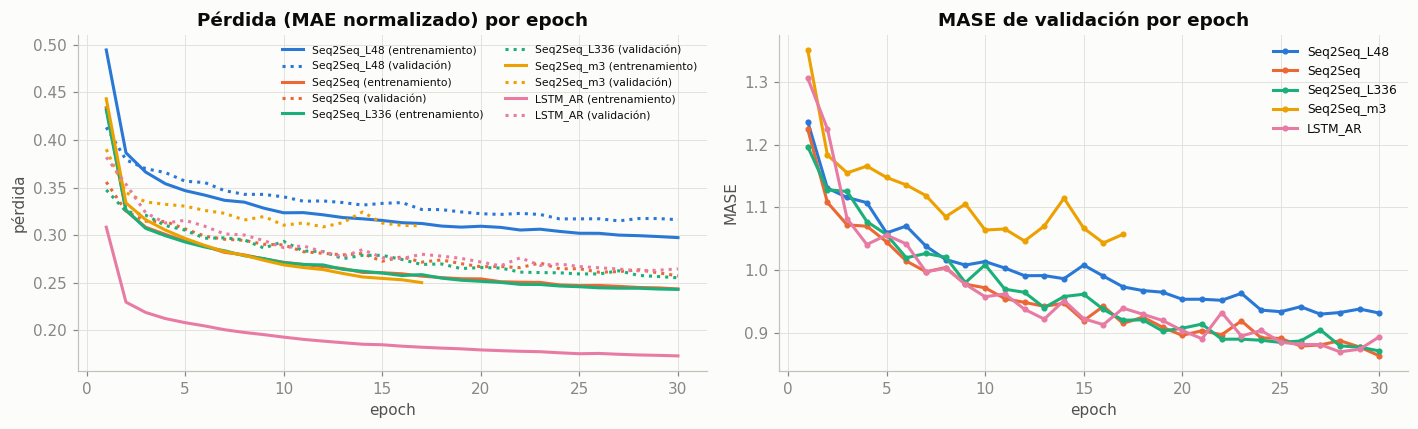

In [15]:
def load_history(run_id):
    for d in (C.RESULTS_DIR, P1_RESULTS):
        p = d / "history" / f"{run_id}.csv"
        if p.exists():
            return pd.read_csv(p)
    raise FileNotFoundError(run_id)


curves = [r for r in ["Seq2Seq_L48", "Seq2Seq", "Seq2Seq_L336", "Seq2Seq_m3", "LSTM_AR"] if r in set(iters["run"])]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, run in enumerate(curves):
    h = load_history(iters.set_index("run").loc[run, "run_id"])
    axes[0].plot(h["epoch"], h["train_loss"], color=PALETTE[k], label=f"{run} (entrenamiento)")
    axes[0].plot(h["epoch"], h["val_loss"], color=PALETTE[k], ls=":", label=f"{run} (validación)")
    axes[1].plot(h["epoch"], h["val_MASE"], color=PALETTE[k], marker="o", ms=3, label=run)
axes[0].set_title("Pérdida (MAE normalizado) por epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("pérdida")
axes[1].set_title("MASE de validación por epoch"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("MASE")
axes[0].legend(fontsize=7, ncol=2); axes[1].legend(fontsize=8)
plt.tight_layout(); savefig(fig, "5_2_curvas_perdida"); plt.show()

**¿Una pérdida de entrenamiento más baja implica siempre un mejor MASE en validación?**

Para cada red propia, la tabla junta la pérdida de entrenamiento mínima, la de validación en la mejor epoch y el MASE de validación. También se calcula la correlación de rangos entre la pérdida de entrenamiento y el MASE de validación.

In [16]:
own_runs = iters[iters["run_id"].notna() & iters["base"].isin(OWN)].copy()
own_runs["train_loss_min"] = [load_history(r)["train_loss"].min() for r in own_runs["run_id"]]
own_runs["val_loss_best"] = [load_history(r)["val_loss"].min() for r in own_runs["run_id"]]
tl = own_runs[["run", "norm", "train_loss_min", "val_loss_best", "val_MASE"]].sort_values("train_loss_min")
display(tl.round(4))
rho = tl["train_loss_min"].rank().corr(tl["val_MASE"].rank())
print(f"Correlación de Spearman (pérdida de entrenamiento vs MASE de validación): {rho:.2f}")

,run,norm,train_loss_min,val_loss_best,val_MASE
28,MLP_norm_global,global,0.0272,0.0238,3.2277
26,LSTM_AR,window,0.1733,0.2626,0.8701
29,MLP_norm_series,series,0.2233,0.2144,0.8833
8,Seq2Seq_L336,window,0.2431,0.2553,0.8715
24,Seq2Seq,window,0.2436,0.2573,0.8636
11,Seq2Seq_m12,window,0.2460,0.2653,0.8936
22,MLP_lr3e-4,window,0.2494,0.2470,0.8285
25,LSTM,window,0.2498,0.2636,0.8916
23,MLP_batch2048,window,0.2499,0.2467,0.8306
9,Seq2Seq_m3,window,0.2502,0.3086,1.0465


Correlación de Spearman (pérdida de entrenamiento vs MASE de validación): 0.13


### Configuración elegida de cada modelo

- **Criterio:** para cada modelo con iteraciones (Seq2Seq, MLP, DLinear, LightGBM, PatchTST y DeepAR) se elige la configuración con menor **MASE de validación**.
- **Qué queda fuera:** las 3 corridas de normalización de la Parte 1, porque usaron menos epochs; su decisión (por ventana) ya está tomada.
- **Si la elegida no es la configuración de referencia** (L = 168, 30 meses y los hiperparámetros de la Parte 1), se evalúa en prueba **una sola vez** y entra a la tabla comparativa. La columna `elegida` de la tabla final marca cuál configuración representa a cada modelo.

In [17]:
def chosen_configs():
    # Modelo base -> nombre de la corrida con menor MASE de validación (la referencia si es equivalente).
    it = pd.read_csv(VAL_CSV)
    it = it[it["base"].isin(OWN | NF_MODELS | {"LightGBM"}) & (it["varied"] != "norm")]
    out = {}
    for base, g in it.groupby("base"):
        best = g.loc[g["val_MASE"].idxmin()]
        same_as_ref = best["varied"] == "base" or (best["varied"] == "history_months" and best["value"] == 30)
        out[base] = (base if same_as_ref else best["run"], best)
    return out


CHOSEN = chosen_configs()
display(pd.DataFrame([{"modelo": b, "elegida": r, "varied": best["varied"], "value": best["value"],
                       "val_MASE": best["val_MASE"]} for b, (r, best) in CHOSEN.items()]).round(4))
for base, (run, best) in CHOSEN.items():
    if run != base:
        _ = run_test(make(run, base, **json.loads(best["spec"])))

,modelo,elegida,varied,value,val_MASE
0,DLinear,DLinear_m3,history_months,3,0.8730
1,DeepAR,DeepAR,base,NaN,1.1090
2,LSTM,LSTM,base,NaN,0.8916
3,LSTM_AR,LSTM_AR,base,NaN,0.8701
4,LightGBM,LightGBM_m12,history_months,12,0.9073
5,MLP,MLP_lr3e-4,lr,0.0003,0.8285
6,NHITS,NHITS,base,NaN,0.8105
7,PatchTST,PatchTST_m3,history_months,3,1.0002
8,Seq2Seq,Seq2Seq,base,NaN,0.8636
9,TCN,TCN,base,NaN,0.9161


[DLinear_m3] prueba cargada de caché: MASE 0.888
[LightGBM_m12] prueba cargada de caché: MASE 0.884
[MLP_lr3e-4] prueba cargada de caché: MASE 0.812
[PatchTST_m3] prueba cargada de caché: MASE 1.006


## Tabla de prueba hasta aquí y mejores modelos

A partir de esta tabla se eligen:

- **El mejor modelo propio**, el de menor MASE de prueba entre las redes de `lab9.models`. Se usa en 5.3.
- **El mejor modelo de deep learning**, entre las redes propias y las de NeuralForecast. Se usa en el reentrenamiento mensual y en las semillas.
  - Chronos queda fuera porque no se entrena.

In [18]:
for _, r in pd.read_csv(VAL_CSV).iterrows():     # reconstruye SPECS de corridas cargadas de caché
    if r["run"] not in SPECS and isinstance(r.get("spec"), str):
        SPECS[r["run"]] = (r["base"], json.loads(r["spec"]))

res2 = pd.read_csv(TEST_CSV)
res_all = pd.concat([res1, res2], ignore_index=True).sort_values("MASE").reset_index(drop=True)
res_all["base"] = res_all["model"].map(base_of)
# Solo la configuración elegida de cada modelo compite por "mejor modelo".
superseded = {b for b, (r, _) in chosen_configs().items() if r != b}
res_all = res_all[~res_all["model"].isin(superseded)].reset_index(drop=True)
best_own = res_all[res_all["base"].isin(OWN)].iloc[0]["model"]
best_dl = res_all[res_all["base"].isin(OWN | NF_MODELS)].iloc[0]["model"]
print(f"Mejor modelo propio: {best_own} | mejor modelo de deep learning: {best_dl}")
display(res_all[["model", "family", "MASE", "MAE", "train_time_s"]].round(3))

Mejor modelo propio: MLP_lr3e-4 | mejor modelo de deep learning: NHITS


,model,family,MASE,MAE,train_time_s
0,ChronosBolt,Fundacional,0.767,40.125,0.000
1,NHITS,Residuales y convolucionales,0.779,40.828,77.421
2,MLP_lr3e-4,MLP y lineales,0.812,41.747,47.363
3,Seq2Seq,Encoder–decoder,0.831,43.140,1222.926
4,LSTM_AR,Recurrentes,0.832,43.304,1291.780
5,TFT,Atención,0.833,42.829,286.692
6,LSTM,Recurrentes,0.871,44.641,913.970
7,NLinear,MLP y lineales,0.882,45.443,31.915
8,LightGBM_m12,Árboles,0.884,43.984,32.364
9,TCN,Residuales y convolucionales,0.884,45.788,146.221


## 5.3 Modelo local contra global

- **Clientes:** 10, elegidos con semilla fija, uno al azar de cada decil del consumo medio. Así quedan cubiertas escalas distintas.
- **Modelo local:** la misma red y configuración que el mejor modelo propio, entrenada solo con la serie de ese cliente (`panel.subset([cid])`). Mismo protocolo: datos hasta 2014-09-30, validación jul–sep para early stopping y prueba con 92 orígenes.
  - Con una sola serie hay ~21 mil ventanas de entrenamiento, así que cada epoch las recorre todas una vez.
- **Modelo global:** son los pronósticos de prueba que ya existen, filtrados a esos 10 clientes.

In [19]:
rng = np.random.default_rng(C.SEED)
pool = stats[stats["unique_id"].isin(panel.ids)].copy()
pool["decil"] = pd.qcut(pool["mean"].rank(method="first"), 10, labels=False)
local_ids = sorted(pool.groupby("decil")["unique_id"].apply(lambda s: rng.choice(s.values)).tolist())
print("Clientes:", local_ids)

glob = load_preds(best_own)
glob_by = ME.by(glob[glob["unique_id"].isin(local_ids)], stats, "unique_id")

for cid in local_ids:
    name = f"{best_own}_local_{cid}"
    if lookup(LOCAL_CSV, name) is not None:
        continue
    m = variant(best_own, name, verbose=False)
    p, info = BT.backtest(m, panel.subset([cid]), split="test", verbose=False)
    s = ME.summary(p, stats)
    upsert(LOCAL_CSV, {"model": name, "unique_id": cid, "MAE_local": s["MAE"], "MASE_local": s["MASE"],
                       "train_time_s": m.train_time, "epochs": len(m.history),
                       "train_windows": m.n_train_windows, "params_total": m.n_params})
    print(f"  {cid}: MASE local {s['MASE']:.3f} | {m.train_time:.0f}s, {len(m.history)} epochs")
    free_gpu()

Clientes: ['MT_003', 'MT_025', 'MT_103', 'MT_130', 'MT_174', 'MT_204', 'MT_230', 'MT_249', 'MT_274', 'MT_303']


,unique_id,mean,cv,MASE_local,MASE_global,mejora_global,train_time_s,epochs
0,MT_003,4.3,3.10,0.079,0.080,-1.2%,1,6
3,MT_130,42.9,1.37,0.240,0.651,-170.9%,6,30
7,MT_249,69.8,0.38,0.869,0.907,-4.4%,7,30
6,MT_230,95.8,0.30,1.050,0.942,+10.3%,3,15
4,MT_174,148.2,0.30,1.242,1.244,-0.2%,2,11
9,MT_303,148.5,0.29,0.953,0.889,+6.7%,7,30
1,MT_025,220.0,0.34,0.746,0.762,-2.1%,4,19
8,MT_274,322.4,0.25,0.846,0.793,+6.3%,7,30
5,MT_204,864.0,0.30,0.785,0.740,+5.7%,3,13
2,MT_103,1122.9,0.57,1.203,1.059,+12.0%,4,20


MASE medio en los 10 clientes: local 0.801 | global 0.807
Tiempo total de los 10 modelos locales: 46s


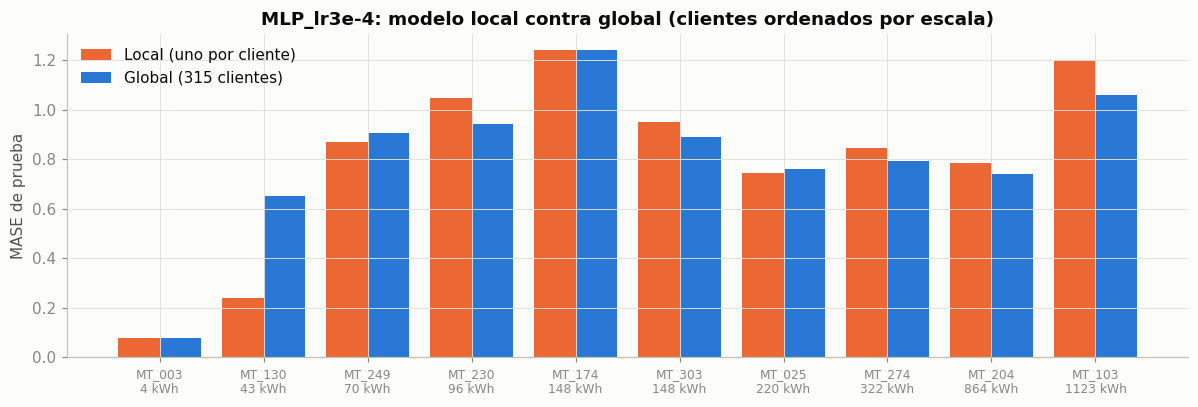

In [20]:
loc_all = pd.read_csv(LOCAL_CSV)
lvg = (loc_all[loc_all["model"].str.startswith(f"{best_own}_local_") & loc_all["unique_id"].isin(local_ids)]
       .merge(glob_by[["unique_id", "MAE", "MASE"]].rename(columns={"MAE": "MAE_global", "MASE": "MASE_global"}),
              on="unique_id")
       .merge(stats[["unique_id", "mean", "std"]], on="unique_id"))
lvg["cv"] = lvg["std"] / lvg["mean"]
lvg["mejora_global"] = 1 - lvg["MASE_global"] / lvg["MASE_local"]       # > 0: el global es mejor
lvg = lvg.sort_values("mean")
display(lvg[["unique_id", "mean", "cv", "MASE_local", "MASE_global", "mejora_global", "train_time_s", "epochs"]]
        .style.format({"mean": "{:.1f}", "cv": "{:.2f}", "MASE_local": "{:.3f}", "MASE_global": "{:.3f}",
                       "mejora_global": "{:+.1%}", "train_time_s": "{:.0f}"}))
print(f"MASE medio en los 10 clientes: local {lvg['MASE_local'].mean():.3f} | global {lvg['MASE_global'].mean():.3f}")
print(f"Tiempo total de los 10 modelos locales: {lvg['train_time_s'].sum():.0f}s")

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(lvg))
ax.bar(x - 0.2, lvg["MASE_local"], 0.4, color=PALETTE[1], label="Local (uno por cliente)")
ax.bar(x + 0.2, lvg["MASE_global"], 0.4, color=PALETTE[0], label="Global (315 clientes)")
ax.set_xticks(x, [f"{u}\n{m:.0f} kWh" for u, m in zip(lvg["unique_id"], lvg["mean"])], fontsize=8)
ax.set_ylabel("MASE de prueba"); ax.set_title(f"{best_own}: modelo local contra global (clientes ordenados por escala)")
ax.legend()
plt.tight_layout(); savefig(fig, "5_3_local_vs_global"); plt.show()

## 4. Reentrenamiento mensual

`backtest(..., refit_every="MS")` reentrena el 1 de octubre, el 1 de noviembre y el 1 de diciembre:

- **Ventana:** expandible; usa todos los datos anteriores al origen.
- **Validación:** los 3 meses previos, solo para early stopping.

**El 1 de octubre la configuración coincide con el entrenamiento único.** La diferencia viene de noviembre y diciembre.

| Modelo | Por qué |
|---|---|
| Mejor modelo de DL | Lo pide el enunciado |
| LightGBM | Su reentrenamiento sí cambia los pesos |
| Mejor baseline: MSTL | Es local y ya se reajusta en cada origen con la historia disponible (`StatsForecastModel.fit` no hace nada). Por construcción, su resultado con reentrenamiento mensual es **idéntico**. Se comprueba abajo con el seasonal naive, que cumple el mismo contrato y es barato. |

In [21]:
refit_rows = [run_test(variant(best_dl, f"{best_dl}_refitMS"), table=REFIT_CSV, refit_every="MS"),
              run_test(variant("LightGBM", "LightGBM_refitMS"), table=REFIT_CSV, refit_every="MS")]

sn = make("SeasonalNaive24_refitMS", "SeasonalNaive24")
p_refit, _ = BT.backtest(sn, panel, split="test", refit_every="MS", verbose=False)
p_once = load_preds("SeasonalNaive24")
same = np.allclose(p_refit.sort_values(["unique_id", "ds"])["y_hat"].values,
                   p_once.sort_values(["unique_id", "ds"])["y_hat"].values)
print("Baselines locales: pronóstico con reentrenamiento mensual idéntico al de una sola vez ->", same)

[NHITS_refitMS] prueba cargada de caché: MASE 0.778
[LightGBM_refitMS] prueba cargada de caché: MASE 0.883


Baselines locales: pronóstico con reentrenamiento mensual idéntico al de una sola vez -> True


In [22]:
def mase_by_month(preds):
    return ME.by(preds.assign(mes=preds["ds"].dt.strftime("%Y-%m")), stats, "mes").set_index("mes")["MASE"]


rows = []
for src in [best_dl, "LightGBM"]:
    for label, name in [("una vez", src), ("mensual", f"{src}_refitMS")]:
        p = load_preds(name)
        rows.append({"modelo": src, "entrenamiento": label, "MASE": ME.summary(p, stats)["MASE"],
                     **mase_by_month(p).to_dict()})
refit_cmp = pd.DataFrame(rows)
display(refit_cmp.style.format({c: "{:.3f}" for c in refit_cmp.columns if c not in ("modelo", "entrenamiento")}))
display(pd.read_csv(REFIT_CSV)[["model", "MASE", "MAE", "train_time_s", "n_fits"]].round(3))

,modelo,entrenamiento,MASE,2014-10,2014-11,2014-12
0,NHITS,una vez,0.779,0.745,0.681,0.907
1,NHITS,mensual,0.778,0.745,0.677,0.910
2,LightGBM,una vez,0.880,0.829,0.769,1.038
3,LightGBM,mensual,0.883,0.828,0.770,1.047


,model,MASE,MAE,train_time_s,n_fits
0,NHITS_refitMS,0.778,40.601,268.286,3
1,LightGBM_refitMS,0.883,44.087,147.824,3


## 6. MASE con H = 168

`backtest(model, panel, H=168)` emite un pronóstico de una semana en cada origen diario cuyo horizonte cabe en la prueba: son 86 orígenes.

| Tipo de modelo | Cómo se adapta a H = 168 |
|---|---|
| Redes (propias y de NeuralForecast) | Se reentrenan con `H=168`: salida de 168 pasos y early stopping con ventanas de 168 h |
| Baselines y LightGBM | Toman el horizonte de `times_future`; funcionan sin cambios |
| Chronos-Bolt | Más allá de 64 pasos realimenta su propia mediana |

**Modelos incluidos:**

- los baselines y LightGBM;
- el mejor propio, el MLP y DLinear;
- PatchTST y N-HiTS, para comparar DLinear contra un Transformer en el horizonte largo;
- Chronos.

In [23]:
H168 = ["Naive", "SeasonalNaive24", "SeasonalNaive168", "LightGBM", "MLP", "DLinear", best_own, "PatchTST",
        "NHITS", "ChronosBolt"] + ([] if QUICK else ["MSTL"])
for src in dict.fromkeys(H168):
    run_test(variant(src, f"{src}_H168", H=168), table=H168_CSV, H=168)
h168 = pd.read_csv(H168_CSV).sort_values("MASE")
display(h168[["model", "family", "MAE", "WAPE", "MASE", "train_time_s", "infer_time_s", "n_origins"]].round(3))

[Naive_H168] prueba cargada de caché: MASE 4.021
[SeasonalNaive24_H168] prueba cargada de caché: MASE 1.204
[SeasonalNaive168_H168] prueba cargada de caché: MASE 1.080
[LightGBM_H168] prueba cargada de caché: MASE 1.055
[MLP_H168] prueba cargada de caché: MASE 0.997
[DLinear_H168] prueba cargada de caché: MASE 0.986
[MLP_lr3e-4_H168] prueba cargada de caché: MASE 0.975
[PatchTST_H168] prueba cargada de caché: MASE 1.082
[NHITS_H168] prueba cargada de caché: MASE 0.950


Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

[ChronosBolt_H168] prueba cargada de caché: MASE 0.919
[MSTL_H168] prueba cargada de caché: MASE 1.039


,model,family,MAE,WAPE,MASE,train_time_s,infer_time_s,n_origins
10,ChronosBolt_H168,Fundacional,50.132,0.085,0.919,0.000,491.537,86
8,NHITS_H168,Residuales y convolucionales,51.121,0.087,0.950,96.810,24.717,86
9,MLP_lr3e-4_H168,MLP y lineales,50.997,0.086,0.975,70.091,0.314,86
5,DLinear_H168,MLP y lineales,52.261,0.089,0.986,51.497,0.550,86
4,MLP_H168,MLP y lineales,52.320,0.089,0.997,68.340,0.512,86
6,Seq2Seq_H168,Encoder–decoder,52.870,0.090,0.998,1131.451,2.242,86
11,MSTL_H168,Baseline,56.669,0.096,1.039,0.000,454.035,86
3,LightGBM_H168,Árboles,55.647,0.094,1.055,31.914,79.504,86
2,SeasonalNaive168_H168,Baseline,57.201,0.097,1.080,0.000,0.702,86
7,PatchTST_H168,Atención,53.155,0.090,1.082,125.162,21.991,86


## 8. Sensibilidad a la semilla

- **Qué se repite:** el mejor modelo de DL, con 3 semillas y la misma configuración.
- **Qué cambia con la semilla:** la inicialización de los pesos, el muestreo de ventanas y el dropout.
- **Semilla 42:** es la corrida de la tabla principal, así que no se repite.

In [24]:
SEEDS = [C.SEED, 7, 2026]
seed_rows = []
for s in SEEDS:
    if s == C.SEED:
        r = res_all.set_index("model").loc[best_dl].to_dict() | {"model": best_dl}
    else:
        r = run_test(variant(best_dl, f"{best_dl}_seed{s}", seed=s), table=SEEDS_CSV)
    seed_rows.append({"semilla": s, "modelo": r["model"], "MASE": r["MASE"], "MAE": r["MAE"],
                      "MASE_xmas": r["MASE_xmas"], "train_time_s": r["train_time_s"]})
seeds = pd.DataFrame(seed_rows)
display(seeds.round(4))
print(f"{best_dl}: MASE {seeds['MASE'].mean():.4f} ± {seeds['MASE'].std(ddof=1):.4f} (media ± desviación estándar, "
      f"{len(seeds)} semillas) | rango {seeds['MASE'].max() - seeds['MASE'].min():.4f}")

[NHITS_seed7] prueba cargada de caché: MASE 0.782
[NHITS_seed2026] prueba cargada de caché: MASE 0.775


,semilla,modelo,MASE,MAE,MASE_xmas,train_time_s
0,42,NHITS,0.7790,40.8276,1.3508,77.4209
1,7,NHITS_seed7,0.7822,40.5897,1.3475,78.7841
2,2026,NHITS_seed2026,0.7746,40.6026,1.2969,62.7491


NHITS: MASE 0.7786 ± 0.0038 (media ± desviación estándar, 3 semillas) | rango 0.0076


## 6. Comparación de resultados

### 6.1 Tabla comparativa final, ordenada por MASE

- **Contenido:** todos los modelos de la sección 5, con la mejor configuración de cada uno (Parte 1 + Parte 2).
- **`MASE_H168`:** MASE con H = 168 donde aplica.
- **`pinball` y `cov_P10_P90`:** solo para los modelos probabilísticos (DeepAR y Chronos).
- **Tiempos:** el de entrenamiento es el ajuste único hasta 2014-09-30. El de inferencia cubre los 92 orígenes de prueba. Chronos solo tiene inferencia.

In [25]:
res2 = pd.read_csv(TEST_CSV)
final = pd.concat([res1, res2], ignore_index=True)
h168 = pd.read_csv(H168_CSV)
final["MASE_H168"] = final["model"].map(dict(zip(h168["model"].str.removesuffix("_H168"), h168["MASE"])))
final = final.sort_values("MASE").reset_index(drop=True)
# elegida = configuración que representa a cada modelo (la de menor MASE de validación).
final["elegida"] = ~final["model"].isin({b for b, (r, _) in chosen_configs().items() if r != b})
final.to_csv(C.RESULTS_DIR / "test_metrics.csv", index=False)

cols = ["model", "elegida", "family", "L", "strategy", "uses_cov", "params_total", "params_trainable", "train_time_s",
        "infer_time_s", "hardware", "MAE", "RMSE", "WAPE", "MAPE", "MASE", "MASE_xmas", "MASE_H168",
        "pinball", "cov_P10_P90"]
display(final[cols].style.format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "WAPE": "{:.3f}", "MAPE": "{:.3f}",
                                  "MASE": "{:.3f}", "MASE_xmas": "{:.3f}", "MASE_H168": "{:.3f}",
                                  "pinball": "{:.2f}", "cov_P10_P90": "{:.1%}", "train_time_s": "{:.0f}",
                                  "infer_time_s": "{:.1f}", "params_total": "{:,.0f}",
                                  "params_trainable": "{:,.0f}"}, na_rep="—"))

,model,elegida,family,L,strategy,uses_cov,params_total,params_trainable,train_time_s,infer_time_s,hardware,MAE,RMSE,WAPE,MAPE,MASE,MASE_xmas,MASE_H168,pinball,cov_P10_P90
0,ChronosBolt,True,Fundacional,2048,multi-salida (directa),False,"47,718,016",0,0,31.4,NVIDIA GeForce RTX 4060 Laptop GPU (solo inferencia),40.12,363.92,0.068,0.088,0.767,1.490,0.919,13.45,80.0%
1,NHITS,True,Residuales y convolucionales,168,multi-salida,True,"4,193,826","4,193,826",77,19.4,NVIDIA GeForce RTX 4060 Laptop GPU,40.83,361.91,0.069,0.091,0.779,1.351,0.950,—,—
2,MLP_lr3e-4,True,MLP y lineales,168,multi-salida,True,"1,049,624","1,049,624",47,0.3,NVIDIA GeForce RTX 4060 Laptop GPU,41.75,358.35,0.070,0.102,0.812,1.437,0.975,—,—
3,Seq2Seq,True,Encoder–decoder,168,encoder–decoder,True,"405,121","405,121",1223,3.1,NVIDIA GeForce RTX 4050 Laptop GPU,43.14,363.98,0.073,0.096,0.831,1.414,0.998,—,—
4,LSTM_AR,True,Recurrentes,168,autorregresiva,True,"202,881","202,881",1292,5.6,NVIDIA GeForce RTX 4050 Laptop GPU,43.30,370.84,0.073,0.101,0.832,1.394,—,—,—
5,TFT,True,Atención,168,encoder–decoder,True,"479,692","479,692",287,19.3,NVIDIA GeForce RTX 4060 Laptop GPU,42.83,366.20,0.072,0.097,0.833,1.434,—,—,—
6,MLP,False,MLP y lineales,168,multi-salida,True,"1,049,624","1,049,624",46,0.3,NVIDIA GeForce RTX 4050 Laptop GPU,43.35,372.21,0.073,0.103,0.836,1.449,0.997,—,—
7,LSTM,True,Recurrentes,168,multi-salida,True,"209,880","209,880",914,2.6,NVIDIA GeForce RTX 4050 Laptop GPU,44.64,369.05,0.075,0.103,0.871,1.566,—,—,—
8,LightGBM,False,Árboles,168,recursiva,True,"201,641","201,641",47,16.7,CPU (16 hilos),43.85,371.58,0.074,0.114,0.880,1.717,1.055,—,—
9,NLinear,True,MLP y lineales,168,multi-salida,False,"4,056","4,056",32,0.3,NVIDIA GeForce RTX 4050 Laptop GPU,45.44,405.37,0.077,0.121,0.882,1.829,—,—,—


### 6.2 Gráfica 1: MASE de prueba contra tiempo de entrenamiento

- **Eje x:** escala logarítmica.
- **Modelos sin entrenamiento:** los baselines locales y Chronos *zero-shot* se dibujan huecos en 1 s, el borde izquierdo.
- **Frontera de Pareto:** une los modelos que nadie supera a la vez en MASE y en tiempo.
- **Naive:** queda fuera de escala y no se dibuja.

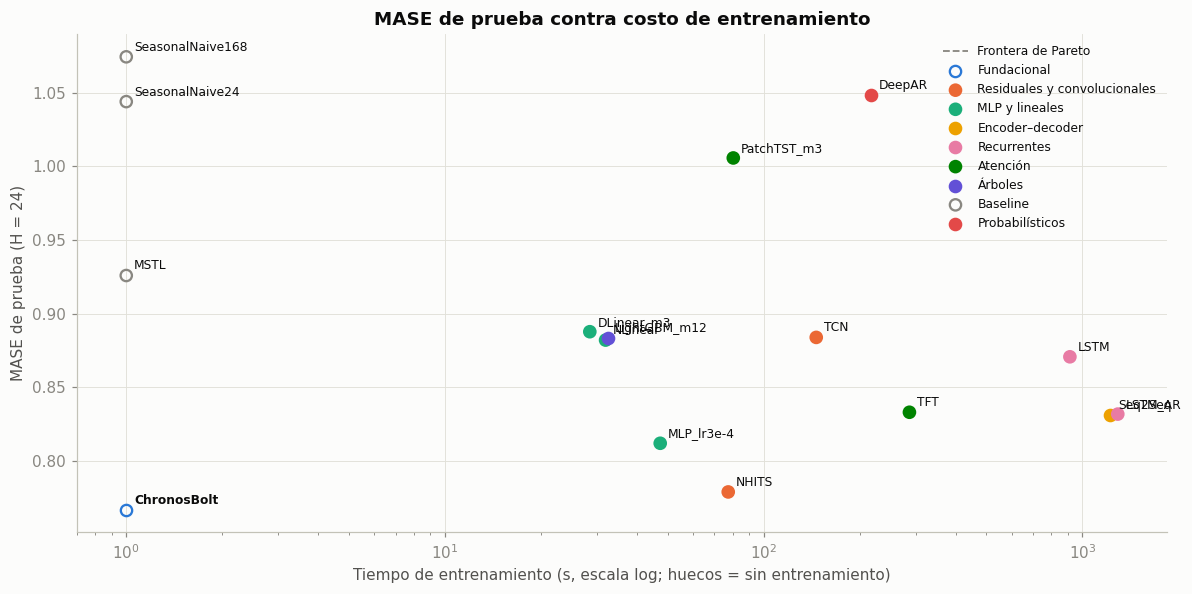

Modelos en la frontera de Pareto: ['ChronosBolt']


In [26]:
pl = final[(final["model"] != "Naive") & final["elegida"]].copy()
X_FLOOR = 1.0
pl["x"] = pl["train_time_s"].fillna(0).clip(lower=X_FLOOR)
pl["sin_entrenar"] = pl["train_time_s"].fillna(0) <= 0
# 9 familias y 8 colores: los baselines van en gris.
fams = [f for f in pl["family"].unique() if f != "Baseline"]
fam_colors = {"Baseline": GRAY, **{f: PALETTE[k % len(PALETTE)] for k, f in enumerate(fams)}}

pareto, best_so_far = [], np.inf
for _, r in pl.sort_values(["x", "MASE"]).iterrows():
    if r["MASE"] < best_so_far:
        pareto.append(r); best_so_far = r["MASE"]
pareto = pd.DataFrame(pareto)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.step(pareto["x"], pareto["MASE"], where="post", color=GRAY, ls="--", lw=1.2, label="Frontera de Pareto", zorder=1)
for fam, g in pl.groupby("family", sort=False):
    c = fam_colors[fam]
    ax.scatter(g["x"], g["MASE"], s=55, zorder=3, label=fam, edgecolors=c, linewidths=1.5,
               facecolors=["none" if h else c for h in g["sin_entrenar"]])
for _, r in pl.iterrows():
    ax.annotate(r["model"], (r["x"], r["MASE"]), xytext=(5, 4), textcoords="offset points", fontsize=8,
                fontweight="bold" if r["model"] in set(pareto["model"]) else "normal")
ax.set_xscale("log")
ax.set_xlabel("Tiempo de entrenamiento (s, escala log; huecos = sin entrenamiento)")
ax.set_ylabel("MASE de prueba (H = 24)")
ax.set_title("MASE de prueba contra costo de entrenamiento")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); savefig(fig, "6_1_pareto_mase_tiempo"); plt.show()
print("Modelos en la frontera de Pareto:", pareto["model"].tolist())

### 6.3 Gráfica 2: MAE por paso del horizonte (h = 1 … 24)

- **Datos:** las curvas de la Parte 1 salen de `results/test_by_horizon.csv`; las nuevas se calculan aquí.
- **Paneles:** como son más de 8 modelos, se dividen en tres.
- **Referencia:** el seasonal naive de 24 h va en gris punteado.
- **Desgloses guardados:** también se guarda el error por hora y por cliente de los modelos nuevos (la sección 4 los pide para cada modelo).
- **Recordatorio:** todos los orígenes son a las 00:00, así que el paso h coincide con la hora h − 1.

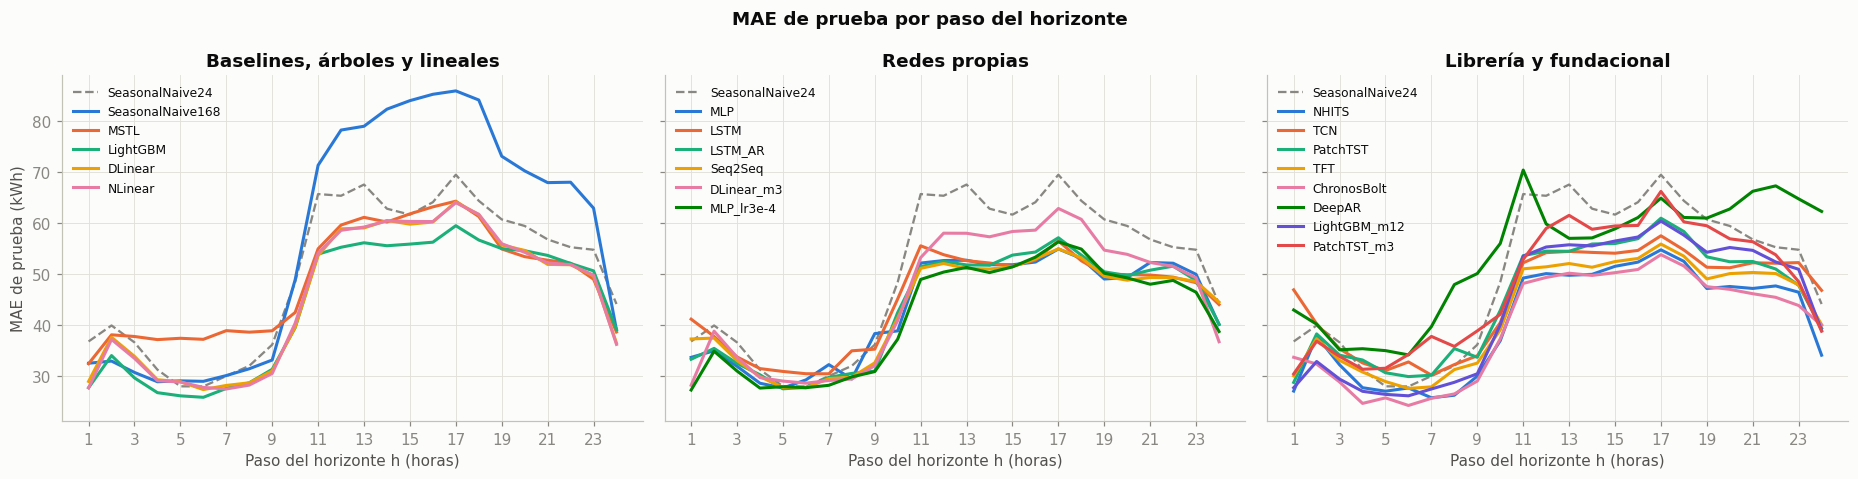

In [27]:
new_models = res2["model"].tolist()
P2 = {n: load_preds(n) for n in new_models}
by_h2 = pd.concat([ME.by(p, stats, "h").assign(model=k) for k, p in P2.items()])
by_hour2 = pd.concat([ME.by(p, stats, "hour").assign(model=k) for k, p in P2.items()])
by_client2 = pd.concat([ME.by(p, stats, "unique_id").assign(model=k) for k, p in P2.items()])
by_h2.to_csv(C.RESULTS_DIR / "test_by_horizon_parte2.csv", index=False)
by_hour2.to_csv(C.RESULTS_DIR / "test_by_hour_parte2.csv", index=False)
by_client2.to_csv(C.RESULTS_DIR / "test_by_client_parte2.csv", index=False)
by_h1 = pd.read_csv(P1_RESULTS / "test_by_horizon.csv")
if QUICK:     # en modo rápido el panel es un subconjunto: se recalcula la Parte 1 sobre esos clientes
    by_h1 = pd.concat([ME.by(load_preds(n), stats, "h").assign(model=n) for n in res1["model"]])
by_h_all = pd.concat([by_h1, by_h2], ignore_index=True)

groups = [("Baselines, árboles y lineales", ["SeasonalNaive168", "MSTL", "LightGBM", "DLinear", "NLinear"]),
          ("Redes propias", ["MLP", "LSTM", "LSTM_AR", "Seq2Seq"] + [n for n in new_models if base_of(n) in OWN]),
          ("Librería y fundacional", [n for n in new_models if base_of(n) not in OWN])]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True)
ref = by_h_all[by_h_all["model"] == "SeasonalNaive24"]
for ax, (title, names) in zip(axes, groups):
    ax.plot(ref["h"], ref["MAE"], color=GRAY, ls="--", lw=1.5, label="SeasonalNaive24")
    for k, n in enumerate([n for n in names if n in set(by_h_all["model"])]):
        t = by_h_all[by_h_all["model"] == n]
        ax.plot(t["h"], t["MAE"], color=PALETTE[k % len(PALETTE)], label=n)
    ax.set_title(title); ax.set_xlabel("Paso del horizonte h (horas)"); ax.set_xticks(range(1, 25, 2))
    ax.legend(fontsize=8)
axes[0].set_ylabel("MAE de prueba (kWh)")
fig.suptitle("MAE de prueba por paso del horizonte", fontweight="bold")
plt.tight_layout(); savefig(fig, "6_2_mae_por_paso_todos"); plt.show()

### 6.4 Gráfica 3: MASE de validación contra meses de historia

- **Datos:** el MASE de validación de las corridas de 5.2 con 3, 12 y 30 meses de historia.
- **Líneas horizontales:** el seasonal naive y Chronos no se entrenan con esa historia.

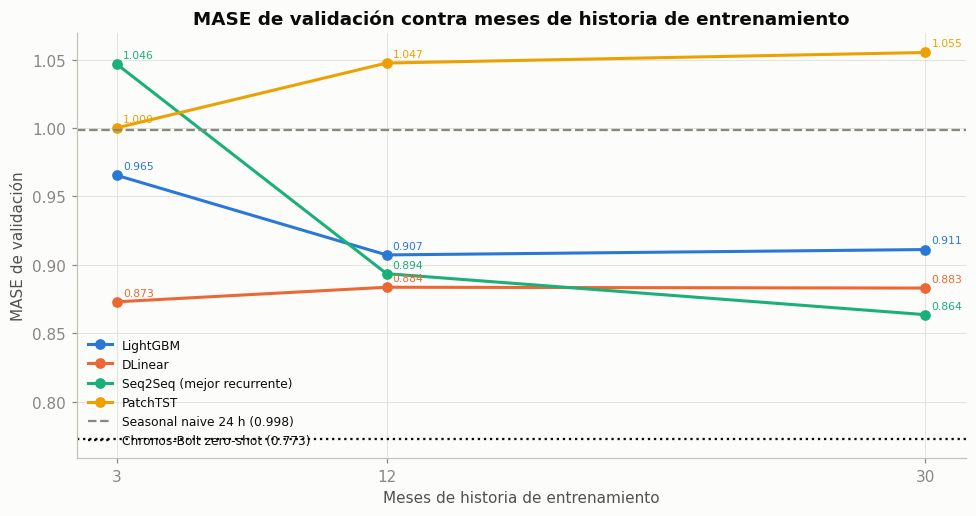

history_months,3.0,12.0,30.0
base,,,
DLinear,0.873,0.884,0.883
DeepAR,NaN,NaN,1.109
LSTM,NaN,NaN,0.892
LSTM_AR,NaN,NaN,0.870
LightGBM,0.965,0.907,0.911
MLP,NaN,NaN,0.859
NHITS,NaN,NaN,0.810
PatchTST,1.000,1.047,1.055
Seq2Seq,1.046,0.894,0.864


In [28]:
iters = pd.read_csv(VAL_CSV)
hm = iters[(iters["varied"].isin(["history_months", "base"])) & (iters["L"].fillna(168) == 168)]
lines = {"LightGBM": "LightGBM", "DLinear": "DLinear", "Seq2Seq": "Seq2Seq (mejor recurrente)", "PatchTST": "PatchTST"}
fig, ax = plt.subplots(figsize=(9, 4.8))
for k, (base, label) in enumerate(lines.items()):
    g = hm[hm["base"] == base].drop_duplicates("history_months", keep="last").sort_values("history_months")
    ax.plot(g["history_months"], g["val_MASE"], color=PALETTE[k], marker="o", label=label)
    for _, r in g.iterrows():
        ax.annotate(f"{r['val_MASE']:.3f}", (r["history_months"], r["val_MASE"]), xytext=(4, 4),
                    textcoords="offset points", fontsize=7, color=PALETTE[k])
for name, label, ls in [("SeasonalNaive24", "Seasonal naive 24 h", "--"), ("ChronosBolt", "Chronos-Bolt zero-shot", ":")]:
    v = iters.set_index("run").loc[name, "val_MASE"]
    ax.axhline(v, color=GRAY if name == "SeasonalNaive24" else "#0b0b0b", ls=ls, lw=1.5, label=f"{label} ({v:.3f})")
ax.set_xticks([3, 12, 30]); ax.set_xlabel("Meses de historia de entrenamiento"); ax.set_ylabel("MASE de validación")
ax.set_title("MASE de validación contra meses de historia de entrenamiento")
ax.legend(fontsize=8)
plt.tight_layout(); savefig(fig, "6_3_mase_vs_historia"); plt.show()
display(hm.pivot_table(index="base", columns="history_months", values="val_MASE").round(3))

### 6.5 Exportación: `preds/test_predictions.parquet`

In [29]:
p1 = pd.read_parquet(P1_PREDS / "test_predictions_parte1.parquet")
p2 = pd.concat([p[["unique_id", "ds", "model", "y_hat"]] for p in P2.values()], ignore_index=True)
allp = pd.concat([p1, p2.rename(columns={"model": "modelo"})], ignore_index=True)
allp = allp[allp["unique_id"].isin(panel.ids)]
allp.to_parquet(C.PREDS_DIR / "test_predictions.parquet", index=False)
assert set(allp["modelo"]) == set(final["model"])
print(f"{len(allp):,} filas | {allp['modelo'].nunique()} modelos: {sorted(allp['modelo'].unique())}")
display(allp.head())

14,605,920 filas | 21 modelos: ['ChronosBolt', 'DLinear', 'DLinear_m3', 'DeepAR', 'LSTM', 'LSTM_AR', 'LightGBM', 'LightGBM_m12', 'MLP', 'MLP_lr3e-4', 'MSTL', 'NHITS', 'NLinear', 'Naive', 'PatchTST', 'PatchTST_m3', 'SeasonalNaive168', 'SeasonalNaive24', 'Seq2Seq', 'TCN', 'TFT']


,unique_id,ds,modelo,y_hat
0,MT_001,2014-10-01 00:00:00,Naive,2.220812
1,MT_001,2014-10-01 01:00:00,Naive,2.220812
2,MT_001,2014-10-01 02:00:00,Naive,2.220812
3,MT_001,2014-10-01 03:00:00,Naive,2.220812
4,MT_001,2014-10-01 04:00:00,Naive,2.220812


## 8. Discusión: números de apoyo

Cada celda reúne los resultados que necesita una pregunta de la sección 8. La interpretación va en el informe.

**¿Qué modelo ganó y por cuánto superó al seasonal naive? ¿La mejora justifica su costo?**

In [30]:
sn24 = final.set_index("model").loc["SeasonalNaive24", "MASE"]
win = final[["model", "family", "MASE", "MAE", "train_time_s", "infer_time_s", "params_total"]].copy()
win["mejora_vs_SN24"] = 1 - win["MASE"] / sn24
display(win.head(8).style.format({"MASE": "{:.3f}", "MAE": "{:.2f}", "train_time_s": "{:.0f}",
                                  "infer_time_s": "{:.1f}", "params_total": "{:,.0f}", "mejora_vs_SN24": "{:.1%}"}))
best = final.iloc[0]["model"]
pc = pd.concat([by_client2, pd.read_csv(P1_RESULTS / "test_by_client.csv")])
pc = pc[pc["unique_id"].isin(panel.ids)].pivot_table(index="unique_id", columns="model", values="MASE")
print(f"{best} le gana al SeasonalNaive24 en {(pc[best] < pc['SeasonalNaive24']).mean():.0%} de los clientes")

,model,family,MASE,MAE,train_time_s,infer_time_s,params_total,mejora_vs_SN24
0,ChronosBolt,Fundacional,0.767,40.12,0,31.4,"47,718,016",26.6%
1,NHITS,Residuales y convolucionales,0.779,40.83,77,19.4,"4,193,826",25.4%
2,MLP_lr3e-4,MLP y lineales,0.812,41.75,47,0.3,"1,049,624",22.2%
3,Seq2Seq,Encoder–decoder,0.831,43.14,1223,3.1,"405,121",20.4%
4,LSTM_AR,Recurrentes,0.832,43.30,1292,5.6,"202,881",20.3%
5,TFT,Atención,0.833,42.83,287,19.3,"479,692",20.2%
6,MLP,MLP y lineales,0.836,43.35,46,0.3,"1,049,624",20.0%
7,LSTM,Recurrentes,0.871,44.64,914,2.6,"209,880",16.6%


ChronosBolt le gana al SeasonalNaive24 en 98% de los clientes


**¿Compite DLinear con los Transformers? ¿En qué horizonte?**

In [31]:
cmp = final[final["model"].map(base_of).isin(["DLinear", "NLinear", "PatchTST", "TFT"]) | (final["model"] == best_own)]
display(cmp[["model", "elegida", "family", "params_total", "train_time_s", "MASE", "MASE_H168", "MASE_xmas"]].round(3))

,model,elegida,family,params_total,train_time_s,MASE,MASE_H168,MASE_xmas
2,MLP_lr3e-4,True,MLP y lineales,1049624,47.363,0.812,0.975,1.437
5,TFT,True,Atención,479692,286.692,0.833,NaN,1.434
9,NLinear,True,MLP y lineales,4056,31.915,0.882,NaN,1.829
12,DLinear,False,MLP y lineales,8112,22.323,0.885,0.986,1.837
13,DLinear_m3,True,MLP y lineales,8112,28.479,0.888,NaN,1.910
15,PatchTST,False,Atención,445467,110.109,0.962,1.082,1.762
16,PatchTST_m3,True,Atención,445467,80.301,1.006,NaN,1.849


**¿Cómo crece el error con el paso del horizonte en cada familia?**

In [32]:
fam = final.set_index("model")["family"]
steps = by_h_all[by_h_all["h"].isin([1, 6, 12, 18, 24])].pivot_table(index="model", columns="h", values="MASE")
steps = steps.loc[[m for m in final["model"] if m in steps.index]]
steps.insert(0, "familia", steps.index.map(fam))
display(steps.round(3))

h,familia,1,6,12,18,24
model,,,,,,
ChronosBolt,Fundacional,0.518,0.539,0.894,0.925,0.788
NHITS,Residuales y convolucionales,0.494,0.570,0.928,0.947,0.747
MLP_lr3e-4,MLP y lineales,0.556,0.595,0.928,0.974,0.823
Seq2Seq,Encoder–decoder,0.604,0.633,0.954,0.973,0.871
LSTM_AR,Recurrentes,0.537,0.635,0.962,0.988,0.868
TFT,Atención,0.590,0.594,0.958,0.985,0.864
MLP,MLP y lineales,0.569,0.651,0.950,0.966,0.846
LSTM,Recurrentes,0.656,0.698,0.989,0.968,0.885
LightGBM,Árboles,0.569,0.636,1.030,1.066,0.858


**¿Qué efecto tuvieron L, la normalización y la historia?**

In [33]:
it = pd.read_csv(VAL_CSV)
for varied in ["L", "norm", "history_months", "hidden", "dropout", "lr", "batch_size", "h_train"]:
    rows = it[(it["varied"] == varied) | ((it["varied"] == "base") & it["base"].isin(it.loc[it["varied"] == varied, "base"]))]
    display(rows[["run", "base", "varied", "value", "L", "history_months", "norm", "train_time_s", "val_MASE"]]
            .sort_values(["base", "val_MASE"]).round(4))

,run,base,varied,value,L,history_months,norm,train_time_s,val_MASE
24,Seq2Seq,Seq2Seq,base,NaN,168,30.0,window,1222.9257,0.8636
8,Seq2Seq_L336,Seq2Seq,L,336,336,30.0,window,1187.2930,0.8715
6,Seq2Seq_L48,Seq2Seq,L,48,48,30.0,window,1072.1728,0.9301


,run,base,varied,value,L,history_months,norm,train_time_s,val_MASE
27,MLP,MLP,base,NaN,168,30.0,window,46.1320,0.8591
30,MLP_norm_window,MLP,norm,window,168,30.0,window,65.8711,0.8765
29,MLP_norm_series,MLP,norm,series,168,30.0,series,176.1305,0.8833
28,MLP_norm_global,MLP,norm,global,168,30.0,global,88.3774,3.2277


,run,base,varied,value,L,history_months,norm,train_time_s,val_MASE
14,DLinear_m3,DLinear,history_months,3,168,3.0,window,47.5498,0.8730
18,DLinear_m30,DLinear,history_months,30,168,30.0,window,28.6202,0.8831
16,DLinear_m12,DLinear,history_months,12,168,12.0,window,43.5026,0.8836
15,LightGBM_m12,LightGBM,history_months,12,168,12.0,NaN,36.6973,0.9073
17,LightGBM_m30,LightGBM,history_months,30,168,30.0,NaN,31.0734,0.9112
13,LightGBM_m3,LightGBM,history_months,3,168,3.0,NaN,31.3588,0.9653
10,PatchTST_m3,PatchTST,history_months,3,168,3.0,ventana (RevIN),87.9912,1.0002
12,PatchTST_m12,PatchTST,history_months,12,168,12.0,ventana (RevIN),49.0327,1.0475
2,PatchTST,PatchTST,base,NaN,168,30.0,ventana (RevIN),110.1094,1.0552
24,Seq2Seq,Seq2Seq,base,NaN,168,30.0,window,1222.9257,0.8636


,run,base,varied,value,L,history_months,norm,train_time_s,val_MASE
27,MLP,MLP,base,NaN,168,30.0,window,46.132,0.8591
20,MLP_hidden1024,MLP,hidden,1024,168,30.0,window,52.137,0.8701


,run,base,varied,value,L,history_months,norm,train_time_s,val_MASE
27,MLP,MLP,base,NaN,168,30.0,window,46.1320,0.8591
21,MLP_dropout0.3,MLP,dropout,0.3,168,30.0,window,79.5463,0.8956


,run,base,varied,value,L,history_months,norm,train_time_s,val_MASE
22,MLP_lr3e-4,MLP,lr,0.0003,168,30.0,window,78.5989,0.8285
27,MLP,MLP,base,NaN,168,30.0,window,46.1320,0.8591


,run,base,varied,value,L,history_months,norm,train_time_s,val_MASE
23,MLP_batch2048,MLP,batch_size,2048,168,30.0,window,41.6655,0.8306
27,MLP,MLP,base,NaN,168,30.0,window,46.1320,0.8591


,run,base,varied,value,L,history_months,norm,train_time_s,val_MASE
7,DeepAR,DeepAR,base,NaN,168,30.0,ventana (standard),217.4670,1.1090
4,DeepAR_htrain1,DeepAR,h_train,1,168,30.0,ventana (standard),105.1238,3.1654


**¿Qué tan cerca quedó Chronos *zero-shot* de los modelos entrenados?**

In [34]:
ch = final.set_index("model").loc["ChronosBolt"]
print(f"Chronos: MASE {ch['MASE']:.3f} (puesto {final.index[final['model'] == 'ChronosBolt'][0] + 1} de {len(final)}) | "
      f"mejor entrenado {final.iloc[0]['model']} {final.iloc[0]['MASE']:.3f} | SN24 {sn24:.3f} | "
      f"inferencia {ch['infer_time_s']:.1f}s, sin entrenamiento")
prob = final[final["pinball"].notna()][["model", "MASE", "MAE", "pinball", "cov_P10_P90", "MASE_xmas", "MASE_H168"]]
display(prob.round(3))

Chronos: MASE 0.767 (puesto 1 de 21) | mejor entrenado ChronosBolt 0.767 | SN24 1.044 | inferencia 31.4s, sin entrenamiento


,model,MASE,MAE,pinball,cov_P10_P90,MASE_xmas,MASE_H168
0,ChronosBolt,0.767,40.125,13.449,0.800,1.490,0.919
18,DeepAR,1.048,53.836,18.965,0.606,1.667,NaN


**¿Qué pasó en Navidad y Año Nuevo? ¿Ayudó la covariable de feriado?**

In [35]:
xm = final[["model", "family", "uses_cov", "MASE", "MASE_xmas"]].copy()
xm["cambio_xmas"] = xm["MASE_xmas"] / xm["MASE"] - 1


def mase_days(name, days=("2014-12-24", "2014-12-25", "2014-12-31")):
    # MASE de un modelo en días puntuales (Nochebuena, Navidad y Nochevieja).
    p = load_preds(name)
    d = p["ds"].dt.normalize()
    return {f"MASE_{pd.Timestamp(x):%d%b}": ME.summary(p[d == pd.Timestamp(x)], stats)["MASE"] for x in days}


xm = xm.join(pd.DataFrame([mase_days(n) for n in xm["model"]], index=xm.index))
day_cols = [c for c in xm.columns if c.startswith("MASE_") and c != "MASE_xmas"]
display(xm.sort_values("MASE_xmas").style.format({"MASE": "{:.3f}", "MASE_xmas": "{:.3f}", "cambio_xmas": "{:+.0%}",
                                                  **{c: "{:.3f}" for c in day_cols}}))
# Promedio por uso de covariables (calendario + feriado), sin el Naive que distorsiona la media.
display(xm[xm["model"] != "Naive"].groupby("uses_cov")[["MASE", "MASE_xmas", "cambio_xmas", *day_cols]].mean().round(3))

,model,family,uses_cov,MASE,MASE_xmas,cambio_xmas,MASE_24Dec,MASE_25Dec,MASE_31Dec
1,NHITS,Residuales y convolucionales,True,0.779,1.351,+73%,1.689,2.929,1.490
4,LSTM_AR,Recurrentes,True,0.832,1.394,+68%,1.728,2.986,1.696
3,Seq2Seq,Encoder–decoder,True,0.831,1.414,+70%,1.735,3.207,1.718
5,TFT,Atención,True,0.833,1.434,+72%,1.745,3.393,1.699
2,MLP_lr3e-4,MLP y lineales,True,0.812,1.437,+77%,1.707,3.411,1.467
6,MLP,MLP y lineales,True,0.836,1.449,+73%,1.732,3.291,1.562
0,ChronosBolt,Fundacional,False,0.767,1.490,+94%,1.699,3.729,1.354
7,LSTM,Recurrentes,True,0.871,1.566,+80%,1.765,3.123,1.855
19,SeasonalNaive168,Baseline,False,1.074,1.623,+51%,1.698,5.190,1.357
11,TCN,Residuales y convolucionales,True,0.884,1.640,+86%,1.735,4.529,1.493


,MASE,MASE_xmas,cambio_xmas,MASE_24Dec,MASE_25Dec,MASE_31Dec
uses_cov,,,,,,
False,0.937,1.833,0.965,1.742,4.519,1.536
True,0.863,1.525,0.769,1.736,3.586,1.622


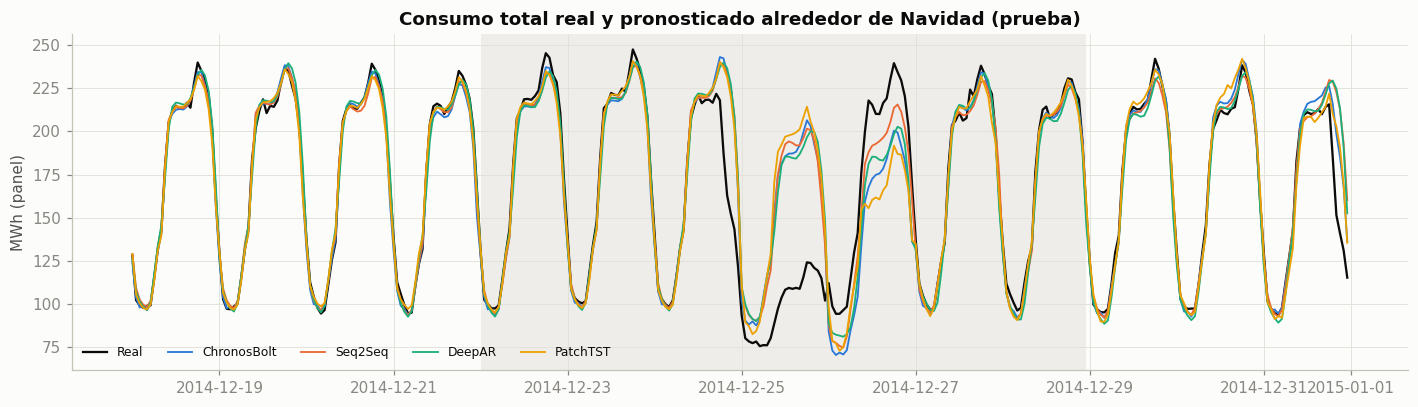

In [36]:
fig, ax = plt.subplots(figsize=(13, 3.8))
sl = slice("2014-12-18", "2014-12-31 23:00")
tot = lambda p: p.groupby("ds")[["y", "y_hat"]].sum().loc[sl] / 1e3
ax.plot(tot(load_preds(best))["y"], color="#0b0b0b", lw=1.5, label="Real")
shown = list(dict.fromkeys([best, "Seq2Seq", "ChronosBolt", "DeepAR", "PatchTST"]))
for k, n in enumerate([n for n in shown if n in set(final["model"])]):
    ax.plot(tot(load_preds(n))["y_hat"], color=PALETTE[k], lw=1.2, label=n)
ax.axvspan(C.XMAS_START, C.XMAS_END, color="#e1e0d9", alpha=0.5, lw=0)
ax.set_ylabel("MWh (panel)"); ax.set_title("Consumo total real y pronosticado alrededor de Navidad (prueba)")
ax.legend(ncol=6, fontsize=8)
plt.tight_layout(); savefig(fig, "8_navidad_modelos_parte2"); plt.show()

**¿Global o por cliente?** Ver la tabla de 5.3. **¿Sensibilidad a la semilla?** Ver la tabla de semillas.

In [37]:
display(lvg[["unique_id", "mean", "cv", "MASE_local", "MASE_global", "mejora_global"]].round(3))
display(seeds.round(4))

,unique_id,mean,cv,MASE_local,MASE_global,mejora_global
0,MT_003,4.331,3.096,0.079,0.080,-0.012
3,MT_130,42.912,1.370,0.240,0.651,-1.709
7,MT_249,69.828,0.377,0.869,0.907,-0.044
6,MT_230,95.772,0.300,1.050,0.942,0.103
4,MT_174,148.193,0.299,1.242,1.244,-0.002
9,MT_303,148.482,0.294,0.953,0.889,0.067
1,MT_025,220.000,0.336,0.746,0.762,-0.021
8,MT_274,322.402,0.248,0.846,0.793,0.063
5,MT_204,864.042,0.304,0.785,0.740,0.057
2,MT_103,1122.888,0.567,1.203,1.059,0.120


,semilla,modelo,MASE,MAE,MASE_xmas,train_time_s
0,42,NHITS,0.7790,40.8276,1.3508,77.4209
1,7,NHITS_seed7,0.7822,40.5897,1.3475,78.7841
2,2026,NHITS_seed2026,0.7746,40.6026,1.2969,62.7491
